# XGBoost: Complete Four-Dimension Course Analysis (English Version)

This notebook extends the original blackbox model's objective, nine original features, and economic rules. **This is a new experiment; previous outputs must not be reused.**
Repayment is coded as 1. A loan is approved only when its predicted repayment probability reaches the threshold. This notebook covers XGBoost only and does not modify other branches.

**Additions**: XPER, PDP/ICE, LIME, disagreements between explanation methods, and customer cases; explanation distances on common observations, decision consistency, input perturbations, and a stability-constraint experiment; FPDP, candidate-variable diagnostics, fairness-mitigation comparisons, conditional statistical parity, binned sufficiency, and equivalence tests for approval rates/TPR/FPR; four-dimension trade-offs and exports.

To run: use the existing project Python environment and set `PROJECT_ROOT` to the project containing `data/`.
Dependencies: `numpy pandas scipy scikit-learn xgboost shap matplotlib joblib`.
Transparent LIME and XPER estimators are implemented in this notebook; the separate lime/XPER packages are not required.
The default is `MODE="full"`. The `smoke` mode checks the workflow only and must not support final project conclusions.
The first run retrains several models, and XPER evaluates all 512 feature coalitions. Allow each section to finish.

**Experimental boundaries**: first reserve a common comparison set (10%) and audit set (10%) from the training pool. For each seed, split the remaining 80% into fit (60%), early-stop (10%), and threshold (10%), with percentages relative to the entire training pool. Use comparison for exploration and model selection, audit for development auditing after freezing the selected approach, and the shared test set only for final reporting.
The team has already explored the original shared test set. A new split does not undo that historical use, which must be disclosed in the final report.

All new figures, models, and CSV files are saved to a separate run directory under the current working directory, without overwriting the original results.
Course page references use PDF viewer page numbers; numbers in parentheses are the printed slide numbers.

In [1]:
from pathlib import Path
from itertools import combinations
from math import comb
import json, hashlib, uuid, warnings
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from scipy.stats import chi2, chi2_contingency, norm, spearmanr
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve
from sklearn.linear_model import Ridge
from IPython.display import display, Markdown
from xgboost import XGBClassifier
import xgboost as xgb
import shap
import joblib

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "app/artifacts/xgb_model.json").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Open this notebook from inside the cloned project directory.")
PROJECT_ROOT = PROJECT_ROOT
MODE = "full"  # full=formal experiment; smoke=small real-data workflow check, not for final comparisons.
assert MODE in {"full", "smoke"}
SEED = 42
SEEDS = [1, 10, 42, 100, 2026] if MODE == "full" else [1, 42]
N_ESTIMATORS = 1500 if MODE == "full" else 100
EARLY_STOPPING = 50 if MODE == "full" else 12
N_JOBS = 4
SAMPLE_LIMIT = None if MODE == "full" else 15000
EXPLAIN_N = 1000 if MODE == "full" else 150
PERM_REPEATS = 5 if MODE == "full" else 2
GRID_SIZE = 12 if MODE == "full" else 5
FPDP_N = 5000 if MODE == "full" else 800
XPER_N = 512 if MODE == "full" else 96
XPER_DRAWS = 8 if MODE == "full" else 2
LIME_N = 3000 if MODE == "full" else 600
BOOTSTRAP_B = 200 if MODE == "full" else 30
THRESHOLDS = np.linspace(0, 1, 101)  # Include the approve-all boundary explicitly, then add the reject-all policy.
THRESHOLDS = np.r_[THRESHOLDS, np.nextafter(1., 2.)]
DELTA, ALPHA, MIN_GROUP_N = 0.02, 0.05, 30
MAX_AUC_LOSS, MAX_PNL_LOSS = 0.01, 0.05  # Mitigation selection: allow at most a 0.01 AUC loss and a 5% positive-P&L loss.
BASE = ["annual_income", "debt_to_income_ratio", "credit_score", "loan_amount",
        "interest_rate", "loan_purpose", "grade_subgrade"]
FEATURES = BASE + ["employment_status", "education_level"]
CAT = ["loan_purpose", "grade_subgrade", "employment_status", "education_level"]
NUM = [c for c in FEATURES if c not in CAT]
AUDIT = ["gender", 
         "marital_status", 
         #"employment_status", 
         #"education_level"
         ]
TARGET, ID = "loan_paid_back", "id"
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:6]
OUT = Path.cwd() / "blackbox_extended_runs" / MODE / RUN_ID
OUT.mkdir(parents=True, exist_ok=False)
TABLES = {}
plt.rcParams.update({"figure.figsize": (9, 4.8), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})

def table(name, data, show=True):
    """Save complete tables consistently; preview only the first 20 rows without discarding remaining results."""
    data = pd.DataFrame(data)
    TABLES[name] = data
    data.to_csv(OUT / (name + ".csv"), index=False, encoding="utf-8-sig")
    if show:
        display(data.head(20))
    return data

def figure(name):
    plt.tight_layout()
    plt.savefig(OUT / (name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

print("Mode:", MODE, "| Output:", OUT)
print("Repayment is the positive class; candidates are selected on comparison only, with audit/test reserved until the approach is frozen.")

Mode: full | Output: /Users/oscar/VSCodeWorkspace/isaf-project/MLModels/blackbox_extended_runs/full/20260924T085553Z_2925d2
Repayment is the positive class; candidates are selected on comparison only, with audit/test reserved until the approach is frozen.


## 1. Data Boundaries and Fixed Holdout Sets
Course p.17 (8) distinguishes variables, predictions, decisions, and actual outcomes. Holding out the 20k observations follows the team agreement.
Category sets, scaling/binning boundaries, and background observations are derived from training data, never from the shared test set.

In [2]:
full = pd.read_csv(PROJECT_ROOT / "data" / "train.csv")
shared_test = pd.read_csv(PROJECT_ROOT / "data/test_eval_20k.csv")
required = set(FEATURES + AUDIT + [TARGET, ID])
for frame in (full, shared_test):
    assert required.issubset(frame.columns)
    assert frame[ID].notna().all() and frame[ID].is_unique
    assert frame[TARGET].isin([0, 1]).all()
    assert not frame[list(required)].isna().any().any(), "Missing values detected; define a handling policy before proceeding."
    assert np.isfinite(frame[NUM]).all().all()
    assert (frame[["loan_amount", "interest_rate"]] >= 0).all().all()
assert len(shared_test) == 20000
assert shared_test[ID].isin(full[ID]).all()
pd.testing.assert_frame_equal(full.set_index(ID).loc[shared_test[ID]].reset_index(),
                              shared_test, check_dtype=False)
pool = full.loc[~full[ID].isin(shared_test[ID])].copy()
assert not pool[ID].isin(shared_test[ID]).any()
if SAMPLE_LIMIT is not None and len(pool) > SAMPLE_LIMIT:
    pool, _ = train_test_split(pool, train_size=SAMPLE_LIMIT, stratify=pool[TARGET], random_state=SEED)
core, held = train_test_split(pool, test_size=.20, stratify=pool[TARGET], random_state=SEED)
comparison, audit = train_test_split(held, test_size=.50, stratify=held[TARGET], random_state=SEED+1)
for a, b in combinations([core, comparison, audit, shared_test], 2):
    assert not set(a[ID]) & set(b[ID])

def split_core(seed):
    # core is 80% of the pool; its 75%/12.5%/12.5% split gives 60%/10%/10% overall.
    fit, rest = train_test_split(core, test_size=.25, stratify=core[TARGET], random_state=seed)
    es, thr = train_test_split(rest, test_size=.5, stratify=rest[TARGET], random_state=seed+1)
    return fit, es, thr

splits = {s: split_core(s) for s in SEEDS}
table("partition_sizes", [{"Partition": k, "Rows": len(v)} for k,v in
    [("core",core),("comparison",comparison),("audit",audit),("shared_test",shared_test)]])
for seed, frames in splits.items():
    manifest = pd.concat([f[[ID]].assign(Partition=label) for label,f in
        zip(["fit","early_stop","threshold"],frames)] +
        [comparison[[ID]].assign(Partition="comparison"), audit[[ID]].assign(Partition="audit")])
    manifest.to_csv(OUT / f"split_ids_{seed}.csv", index=False)

,Partition,Rows
0,core,459195
1,comparison,57399
2,audit,57400
3,shared_test,20000


## 2. Economic Rules, Model Wrappers, and Evaluation Utilities
p.202 (169): P&L depends on decisions and outcomes; the 60% loss rate is a project assumption.
The original XGBoost parameters are retained. Category levels are learned from each model's fit sample and kept consistent during prediction.

In [3]:
def profits(df, approve):
    y = df[TARGET].to_numpy(int)
    amt, rate = df["loan_amount"].to_numpy(), df["interest_rate"].to_numpy()
    return np.asarray(approve) * np.where(y == 1, amt * rate / 100., -.60 * amt)

def threshold_search(df, p):
    rows = [{"Threshold": float(t), "PNL": float(profits(df,p>=t).sum()),
             "Approval": float(np.mean(p>=t))} for t in THRESHOLDS]
    curve = pd.DataFrame(rows)
    # Break P&L ties by choosing the first grid threshold for deterministic selection.
    return float(curve.loc[curve.PNL.idxmax(), "Threshold"]), curve

def metrics(df, p, threshold):
    y, a = df[TARGET].to_numpy(int), np.asarray(p)>=threshold
    fpr,tpr,_ = roc_curve(y,p)
    return {"N":len(df), "AUC":roc_auc_score(y,p), "AP_repaid":average_precision_score(y,p),
            "AP_default":average_precision_score(1-y,1-p), "Gini":2*roc_auc_score(y,p)-1,
            "KS":np.max(tpr-fpr), "Brier":brier_score_loss(y,p),
            "Accuracy":np.mean(a==y), "PNL":profits(df,a).sum(),
            "PNL_per_applicant":profits(df,a).mean(), "Approval":a.mean(),
            "Default_among_approved":np.mean(y[a]==0) if a.any() else np.nan,
            "Threshold":threshold}

def encode(df, bundle):
    X = df[bundle["features"]].copy()
    for col in bundle["features"]:
        if col not in bundle["categories"]:
            X[col] = pd.to_numeric(X[col], errors="raise")
    for col, levels in bundle["categories"].items():
        X[col] = pd.Categorical(X[col], categories=levels)
    return X

def predict(bundle, df, margin=False):
    X = encode(df,bundle)
    raw = bundle["model"].get_booster().predict(
        xgb.DMatrix(X,enable_categorical=True), output_margin=True,
        iteration_range=(0,bundle["model"].best_iteration+1))
    return raw if margin else expit(raw)

def fit_bundle(seed, features=FEATURES, weight=None, anchor=None, strength=0., training_frames=None):
    fit,es,thr = splits[seed] if training_frames is None else training_frames
    categories = {c:sorted(fit[c].unique()) for c in features if c in CAT}
    bundle = {"features":list(features),"categories":categories,"seed":seed}
    objective = "binary:logistic"
    if anchor is not None:
        # Function-space stability extension: CE(y,sigmoid(z)) + lambda/2 * (z-z_ref)^2.
        # p.228 (194) penalizes explanation distances; here we explicitly use raw-score distances on identical inputs instead.
        ref = predict(anchor, fit, margin=True)
        def objective(y, z):
            p = expit(z)
            return p-y+strength*(z-ref), p*(1-p)+strength
    model = XGBClassifier(objective=objective, eval_metric="auc", n_estimators=N_ESTIMATORS,
        max_depth=5, learning_rate=.05, min_child_weight=5, subsample=.8,
        colsample_bytree=.8, reg_alpha=.5, reg_lambda=5., scale_pos_weight=1.,
        enable_categorical=True, tree_method="hist", early_stopping_rounds=EARLY_STOPPING,
        random_state=seed, n_jobs=N_JOBS)
    model.fit(encode(fit,bundle),fit[TARGET],sample_weight=weight,
              eval_set=[(encode(es,bundle),es[TARGET])],verbose=False)
    bundle["model"] = model
    bundle["threshold"], bundle["threshold_curve"] = threshold_search(thr,predict(bundle,thr))
    return bundle

## 3. Baseline Models, Common Validation Performance, and Economic Thresholds
All five seeds use the same comparison sample. The final baseline seed is fixed in advance at 42, rather than selected for its performance.
This section shows development results only. Predictions on the shared test set are evaluated at the end.

Baseline model completed 1 trees= 985
Baseline model completed 10 trees= 1196
Baseline model completed 42 trees= 1052
Baseline model completed 100 trees= 838
Baseline model completed 2026 trees= 1021


,Seed,N,AUC,AP_repaid,AP_default,Gini,KS,Brier,Accuracy,PNL,PNL_per_applicant,Approval,Default_among_approved,Threshold
0,1,57399,0.920185,0.974639,0.830612,0.840370,0.677325,0.072509,0.863290,5.208061e+07,907.343432,0.744595,0.055383,0.80
1,10,57399,0.920367,0.974619,0.831443,0.840734,0.679069,0.072273,0.837349,5.194294e+07,904.945114,0.704612,0.048561,0.84
2,42,57399,0.920491,0.974680,0.831286,0.840983,0.680129,0.072263,0.837157,5.194254e+07,904.938150,0.704071,0.048351,0.84
3,100,57399,0.920229,0.974542,0.831337,0.840457,0.680111,0.072377,0.844074,5.196517e+07,905.332241,0.714786,0.050283,0.83
4,2026,57399,0.920302,0.974597,0.831168,0.840604,0.678152,0.072355,0.858935,5.207003e+07,907.159101,0.736999,0.053755,0.81


,index,mean,std,min,max
0,N,5.739900e+04,0.000000,5.739900e+04,5.739900e+04
1,AUC,9.203148e-01,0.000121,9.201848e-01,9.204913e-01
2,AP_repaid,9.746154e-01,0.000051,9.745423e-01,9.746798e-01
3,AP_default,8.311691e-01,0.000327,8.306118e-01,8.314427e-01
4,Gini,8.406295e-01,0.000242,8.403695e-01,8.409825e-01
5,KS,6.789570e-01,0.001228,6.773245e-01,6.801290e-01
6,Brier,7.235529e-02,0.000099,7.226328e-02,7.250872e-02
7,Accuracy,8.481611e-01,0.012244,8.371574e-01,8.632903e-01
8,PNL,5.200026e+07,69228.511263,5.194254e+07,5.208061e+07
9,PNL_per_applicant,9.059436e+02,1.206093,9.049381e+02,9.073434e+02


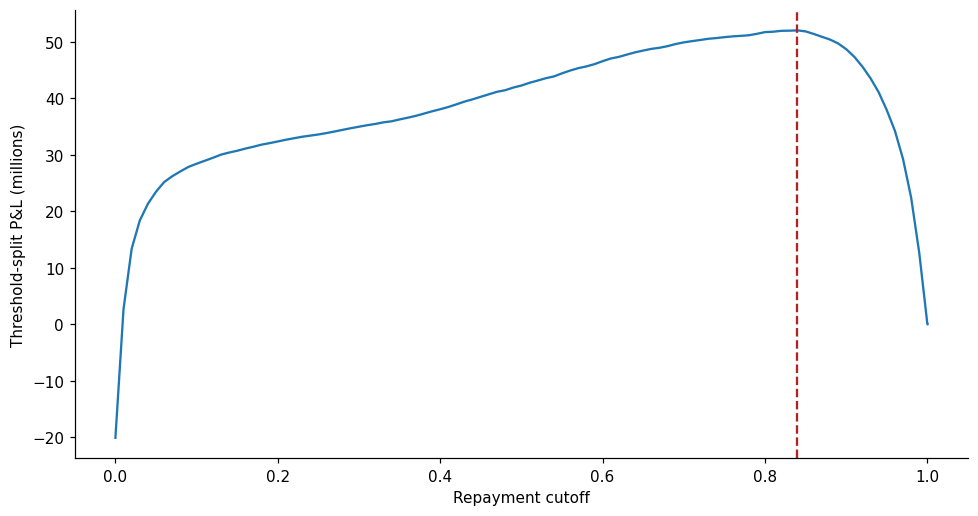

,Policy,PNL
0,Approve all,-2.039572e+07
1,Reject all,0.000000e+00
2,Fixed validation threshold,5.194254e+07


,Policy,PNL
0,Approve all,-2.039572e+07
1,Reject all,0.000000e+00
2,Fixed validation threshold,5.194254e+07


In [4]:
models = {}
for seed in SEEDS:
    models[seed] = fit_bundle(seed)
    print("Baseline model completed",seed,"trees=",models[seed]["model"].best_iteration+1, flush=True)
baseline = models[SEED]
p_comp = predict(baseline,comparison)
performance = table("seed_performance", [dict(Seed=s,**metrics(comparison,predict(m,comparison),m["threshold"]))
                                             for s,m in models.items()])
table("seed_performance_summary",performance.drop(columns="Seed").agg(["mean","std","min","max"]).T.reset_index())
curve = baseline["threshold_curve"]
table("baseline_threshold_curve",curve,False)
plt.plot(curve.Threshold,curve.PNL/1e6)
plt.axvline(baseline["threshold"],c="firebrick",ls="--")
plt.xlabel("Repayment cutoff"); plt.ylabel("Threshold-split P&L (millions)")
figure("threshold_curve")
table("economic_references_comparison",[
    {"Policy":"Approve all","PNL":profits(comparison,np.ones(len(comparison),bool)).sum()},
    {"Policy":"Reject all","PNL":0},
    {"Policy":"Fixed validation threshold","PNL":profits(comparison,p_comp>=baseline["threshold"]).sum()}])

## 4. Group Metrics and Statistical Inference
p.276 (240): statistical parity compares approval rates. p.278 (242): separation compares TPR/FPR.
p.310, 314–315 (272, 276–277): TOST supports a difference within ±delta only when both one-sided tests reject their null hypotheses.
This implementation uses a normal approximation instead of the slides' finite-sample t critical values. Holm correction is an additional project safeguard.

In [5]:
def holm(values):
    p = np.asarray(values,float)
    finite = np.isfinite(p)
    result = np.full(len(p),np.nan)
    if finite.any():
        v=p[finite]; order=np.argsort(v); adj=np.empty(len(v))
        adj[order]=np.minimum(1,np.maximum.accumulate((len(v)-np.arange(len(v)))*v[order]))
        result[finite]=adj
    return result

def group_metrics(df,p,threshold):
    y,a = df[TARGET].to_numpy(int),np.asarray(p)>=threshold
    rows=[]
    for attr in AUDIT:
        for group in sorted(df[attr].unique()):
            m=(df[attr].to_numpy()==group); pos=m&(y==1); neg=m&(y==0)
            rows.append({"Attribute":attr,"Group":group,"N":int(m.sum()),
                "Approved":int(a[m].sum()),"Repaid_N":int(pos.sum()),"Default_N":int(neg.sum()),
                "Approved_repaid":int(a[pos].sum()),"Approved_default":int(a[neg].sum()),
                "Approval":a[m].mean(),"TPR":a[pos].mean() if pos.any() else np.nan,
                "FPR":a[neg].mean() if neg.any() else np.nan,
                "Precision":y[m&a].mean() if (m&a).any() else np.nan,
                "Brier":np.mean((np.asarray(p)[m]-y[m])**2),
                "AUC":roc_auc_score(y[m],np.asarray(p)[m]) if len(np.unique(y[m]))==2 else np.nan})
    return pd.DataFrame(rows)

def gaps(details):
    rows=[]
    for attr,g in details.groupby("Attribute",sort=False):
        # Retain small groups in detailed tables; selection gaps include only groups meeting the predefined minimum size.
        g=g[g.N>=MIN_GROUP_N]
        row={"Attribute":attr,"Eligible_groups":len(g)}
        for col in ["Approval","TPR","FPR"]:
            row[col+"_gap"]=g[col].max()-g[col].min() if len(g)>=2 else np.nan
        row["EO_gap"]=max(row["TPR_gap"],row["FPR_gap"])
        row["DI_ratio"]=g.Approval.min()/g.Approval.max() if len(g)>=2 and g.Approval.max()>0 else np.nan
        rows.append(row)
    return pd.DataFrame(rows)

def equivalence_tests(details):
    # CI90 gives unadjusted pairwise intervals; formal equivalence conclusions use only the Holm-adjusted p-values below.
    rows=[]
    for attr,g in details.groupby("Attribute"):
        for (_,a),(_,b) in combinations(list(g.iterrows()),2):
            for metric,k,n in [("Approval","Approved","N"),("TPR","Approved_repaid","Repaid_N"),
                                ("FPR","Approved_default","Default_N")]:
                na,nb=float(a[n]),float(b[n]); ka,kb=float(a[k]),float(b[k])
                diff=ka/na-kb/nb if min(na,nb)>0 else np.nan
                ok=min(na,nb)>=MIN_GROUP_N and min(ka,na-ka,kb,nb-kb)>=5
                se=np.sqrt(ka/na*(1-ka/na)/na+kb/nb*(1-kb/nb)/nb) if ok else np.nan
                pv=max(norm.sf((diff+DELTA)/se),norm.cdf((diff-DELTA)/se)) if ok and se>0 else np.nan
                rows.append(dict(Attribute=attr,Group_A=a.Group,Group_B=b.Group,Metric=metric,
                    Difference=diff,N_A=na,N_B=nb,Delta=DELTA,p_raw=pv,
                    CI90_low=diff-1.644854*se,CI90_high=diff+1.644854*se))
    out=pd.DataFrame(rows);out["p_Holm"]=holm(out.p_raw)
    out["Conclusion"]=np.where(out.p_Holm.isna(),"not assessed: sparse counts",
                           np.where(out.p_Holm<ALPHA,"equivalent within delta","equivalence not established"))
    return out

fair_comp=group_metrics(comparison,p_comp,baseline["threshold"])
table("fairness_comparison",fair_comp)
table("fairness_gaps_comparison",gaps(fair_comp))
table("tost_comparison",equivalence_tests(fair_comp))

,Attribute,Group,N,Approved,Repaid_N,Default_N,Approved_repaid,Approved_default,Approval,TPR,FPR,Precision,Brier,AUC
0,gender,Female,29429,20767,23638,5791,19792,975,0.705664,0.837296,0.168365,0.953051,0.071067,0.920770
1,gender,Male,27596,19371,21908,5688,18405,966,0.701950,0.840104,0.169831,0.950132,0.073519,0.920257
2,gender,Other,374,275,306,68,262,13,0.735294,0.856209,0.191176,0.952727,0.073781,0.917436
3,marital_status,Divorced,2051,1437,1639,412,1362,75,0.700634,0.830995,0.182039,0.947808,0.077803,0.904223
4,marital_status,Married,26741,18877,21356,5385,17980,897,0.705920,0.841918,0.166574,0.952482,0.072157,0.921590
5,marital_status,Single,27979,19654,22351,5628,18692,962,0.702455,0.836294,0.170931,0.951053,0.072165,0.920307
6,marital_status,Widowed,628,445,506,122,425,20,0.708599,0.839921,0.163934,0.955056,0.063037,0.932985


,Attribute,Eligible_groups,Approval_gap,TPR_gap,FPR_gap,EO_gap,DI_ratio
0,gender,3,0.033345,0.018913,0.022812,0.022812,0.954651
1,marital_status,4,0.007965,0.010923,0.018104,0.018104,0.988760


,Attribute,Group_A,Group_B,Metric,Difference,N_A,N_B,Delta,p_raw,CI90_low,CI90_high,p_Holm,Conclusion
0,gender,Female,Male,Approval,0.003715,29429.0,27596.0,0.02,1.039197e-05,-0.002578,0.010008,0.000270,equivalent within delta
1,gender,Female,Male,TPR,-0.002808,23638.0,21908.0,0.02,3.102024e-07,-0.008481,0.002865,0.000008,equivalent within delta
2,gender,Female,Male,FPR,-0.001467,5791.0,5688.0,0.02,4.041650e-03,-0.012976,0.010043,0.092958,equivalence not established
3,gender,Female,Other,Approval,-0.029630,29429.0,374.0,0.02,6.624957e-01,-0.067407,0.008147,1.000000,equivalence not established
4,gender,Female,Other,TPR,-0.018913,23638.0,306.0,0.02,4.785494e-01,-0.052142,0.014315,1.000000,equivalence not established
5,gender,Female,Other,FPR,-0.022812,5791.0,68.0,0.02,5.233859e-01,-0.101664,0.056040,1.000000,equivalence not established
6,gender,Male,Other,Approval,-0.033345,27596.0,374.0,0.02,7.192946e-01,-0.071140,0.004451,1.000000,equivalence not established
7,gender,Male,Other,TPR,-0.016105,21908.0,306.0,0.02,4.235904e-01,-0.049349,0.017138,1.000000,equivalence not established
8,gender,Male,Other,FPR,-0.021345,5688.0,68.0,0.02,5.111921e-01,-0.100208,0.057517,1.000000,equivalence not established
9,marital_status,Divorced,Married,Approval,-0.005286,2051.0,26741.0,0.02,8.034548e-02,-0.022540,0.011968,1.000000,equivalence not established


,Attribute,Group_A,Group_B,Metric,Difference,N_A,N_B,Delta,p_raw,CI90_low,CI90_high,p_Holm,Conclusion
0,gender,Female,Male,Approval,0.003715,29429.0,27596.0,0.02,1.039197e-05,-0.002578,0.010008,0.000270,equivalent within delta
1,gender,Female,Male,TPR,-0.002808,23638.0,21908.0,0.02,3.102024e-07,-0.008481,0.002865,0.000008,equivalent within delta
2,gender,Female,Male,FPR,-0.001467,5791.0,5688.0,0.02,4.041650e-03,-0.012976,0.010043,0.092958,equivalence not established
3,gender,Female,Other,Approval,-0.029630,29429.0,374.0,0.02,6.624957e-01,-0.067407,0.008147,1.000000,equivalence not established
4,gender,Female,Other,TPR,-0.018913,23638.0,306.0,0.02,4.785494e-01,-0.052142,0.014315,1.000000,equivalence not established
5,gender,Female,Other,FPR,-0.022812,5791.0,68.0,0.02,5.233859e-01,-0.101664,0.056040,1.000000,equivalence not established
6,gender,Male,Other,Approval,-0.033345,27596.0,374.0,0.02,7.192946e-01,-0.071140,0.004451,1.000000,equivalence not established
7,gender,Male,Other,TPR,-0.016105,21908.0,306.0,0.02,4.235904e-01,-0.049349,0.017138,1.000000,equivalence not established
8,gender,Male,Other,FPR,-0.021345,5688.0,68.0,0.02,5.111921e-01,-0.100208,0.057517,1.000000,equivalence not established
9,marital_status,Divorced,Married,Approval,-0.005286,2051.0,26741.0,0.02,8.034548e-02,-0.022540,0.011968,1.000000,equivalence not established


## 5. SHAP, Permutation Importance, and Disagreement Between Explanation Methods
p.188 (155) checks additivity; p.190 (157) summarizes global importance using mean absolute SHAP values.
p.207 (174): permutation importance measures the drop in performance. The methods have different units and answer different questions, so compare rankings rather than raw values.
The explain sample is fixed across all seeds. Categories are not artificially encoded as ordered numbers.

,Feature,PI_mean,PI_std,Mean_abs_SHAP,PI_rank,SHAP_rank,Rank_difference
7,employment_status,0.173671,0.012736,1.280132,1.0,1.0,0.0
1,debt_to_income_ratio,0.095434,0.013001,0.895828,2.0,2.0,0.0
2,credit_score,0.033124,0.016136,0.625674,3.0,3.0,0.0
6,grade_subgrade,0.004888,0.001906,0.189649,4.0,4.0,0.0
3,loan_amount,-0.000651,0.001083,0.112268,8.0,5.0,3.0
0,annual_income,0.003071,0.001959,0.091972,5.0,6.0,1.0
4,interest_rate,-0.001337,0.002214,0.089984,9.0,7.0,2.0
8,education_level,-0.000003,0.001246,0.052566,7.0,8.0,1.0
5,loan_purpose,0.000887,0.001289,0.052095,6.0,9.0,3.0


PI/SHAP rank Spearman: 0.7999999999999999


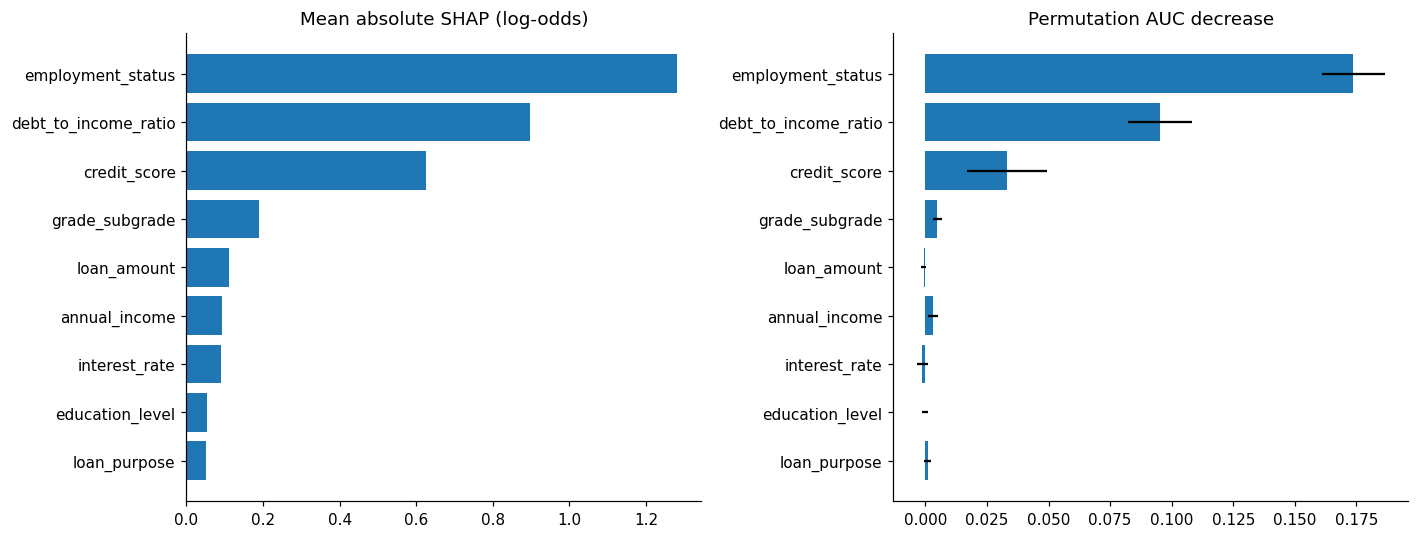

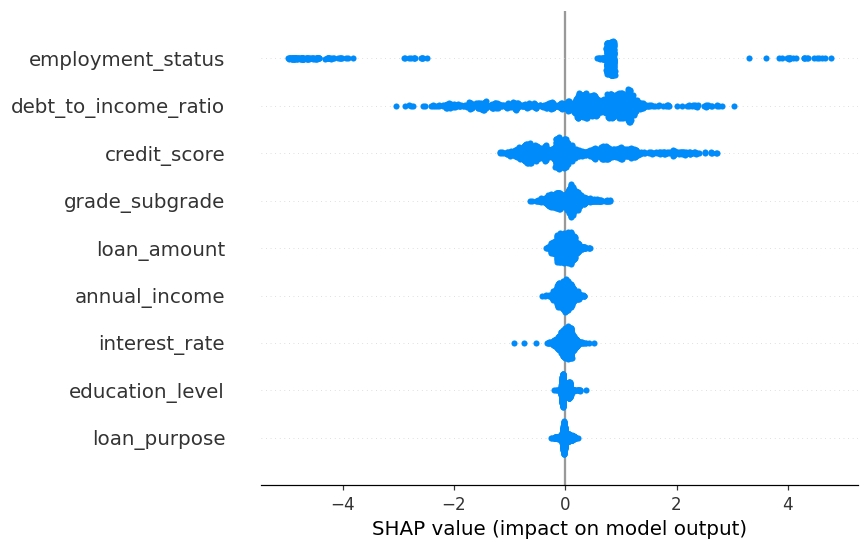

Ranking differences reflect the distinction between prediction contributions and performance dependence; they do not automatically invalidate either explanation.


In [6]:
explain_df=comparison.sample(min(EXPLAIN_N,len(comparison)),random_state=SEED)
def contributions(bundle,df):
    dm=xgb.DMatrix(encode(df,bundle),enable_categorical=True)
    c=bundle["model"].get_booster().predict(dm,pred_contribs=True,
               iteration_range=(0,bundle["model"].best_iteration+1))
    np.testing.assert_allclose(c.sum(axis=1),predict(bundle,df,True),rtol=1e-4,atol=1e-4)
    return c[:,:-1],c[:,-1]

def permutation_scores(bundle,df):
    y=df[TARGET].to_numpy(); original=roc_auc_score(y,predict(bundle,df)); rng=np.random.default_rng(SEED)
    rows=[]
    for c in bundle["features"]:
        drops=[]
        for _ in range(PERM_REPEATS):
            shuffled=df.copy();shuffled[c]=rng.permutation(shuffled[c].to_numpy())
            drops.append(original-roc_auc_score(y,predict(bundle,shuffled)))
        rows.append({"Feature":c,"PI_mean":np.mean(drops),"PI_std":np.std(drops,ddof=1)})
    return pd.DataFrame(rows)

shap_values,shap_base=contributions(baseline,explain_df)
importance=permutation_scores(baseline,explain_df)
importance["Mean_abs_SHAP"]=np.abs(shap_values).mean(axis=0)
importance["PI_rank"]=importance.PI_mean.rank(ascending=False)
importance["SHAP_rank"]=importance.Mean_abs_SHAP.rank(ascending=False)
importance["Rank_difference"]=(importance.PI_rank-importance.SHAP_rank).abs()
table("importance_and_disagreement",importance.sort_values("SHAP_rank"))
print("PI/SHAP rank Spearman:",spearmanr(importance.PI_rank,importance.SHAP_rank).statistic)
plot=importance.sort_values("Mean_abs_SHAP")
fig,axes=plt.subplots(1,2,figsize=(13,5))
axes[0].barh(plot.Feature,plot.Mean_abs_SHAP);axes[0].set_title("Mean absolute SHAP (log-odds)")
axes[1].barh(plot.Feature,plot.PI_mean,xerr=plot.PI_std);axes[1].set_title("Permutation AUC decrease")
figure("importance_methods")
shap.summary_plot(shap_values,feature_names=FEATURES,show=False)
figure("shap_beeswarm")
print("Ranking differences reflect the distinction between prediction contributions and performance dependence; they do not automatically invalidate either explanation.")

## 6. PDP and ICE: How Predictions Change with Features
PDP averages predictions over a fixed sample; ICE retains each customer's curve. Neither represents a causal effect.
Quantile grids are learned from fit data. Changing one feature at a time may produce combinations that are rare in practice.
Numerical features receive PDP+ICE plots; categorical features receive PDP plots without connecting categories as continuous numerical values.

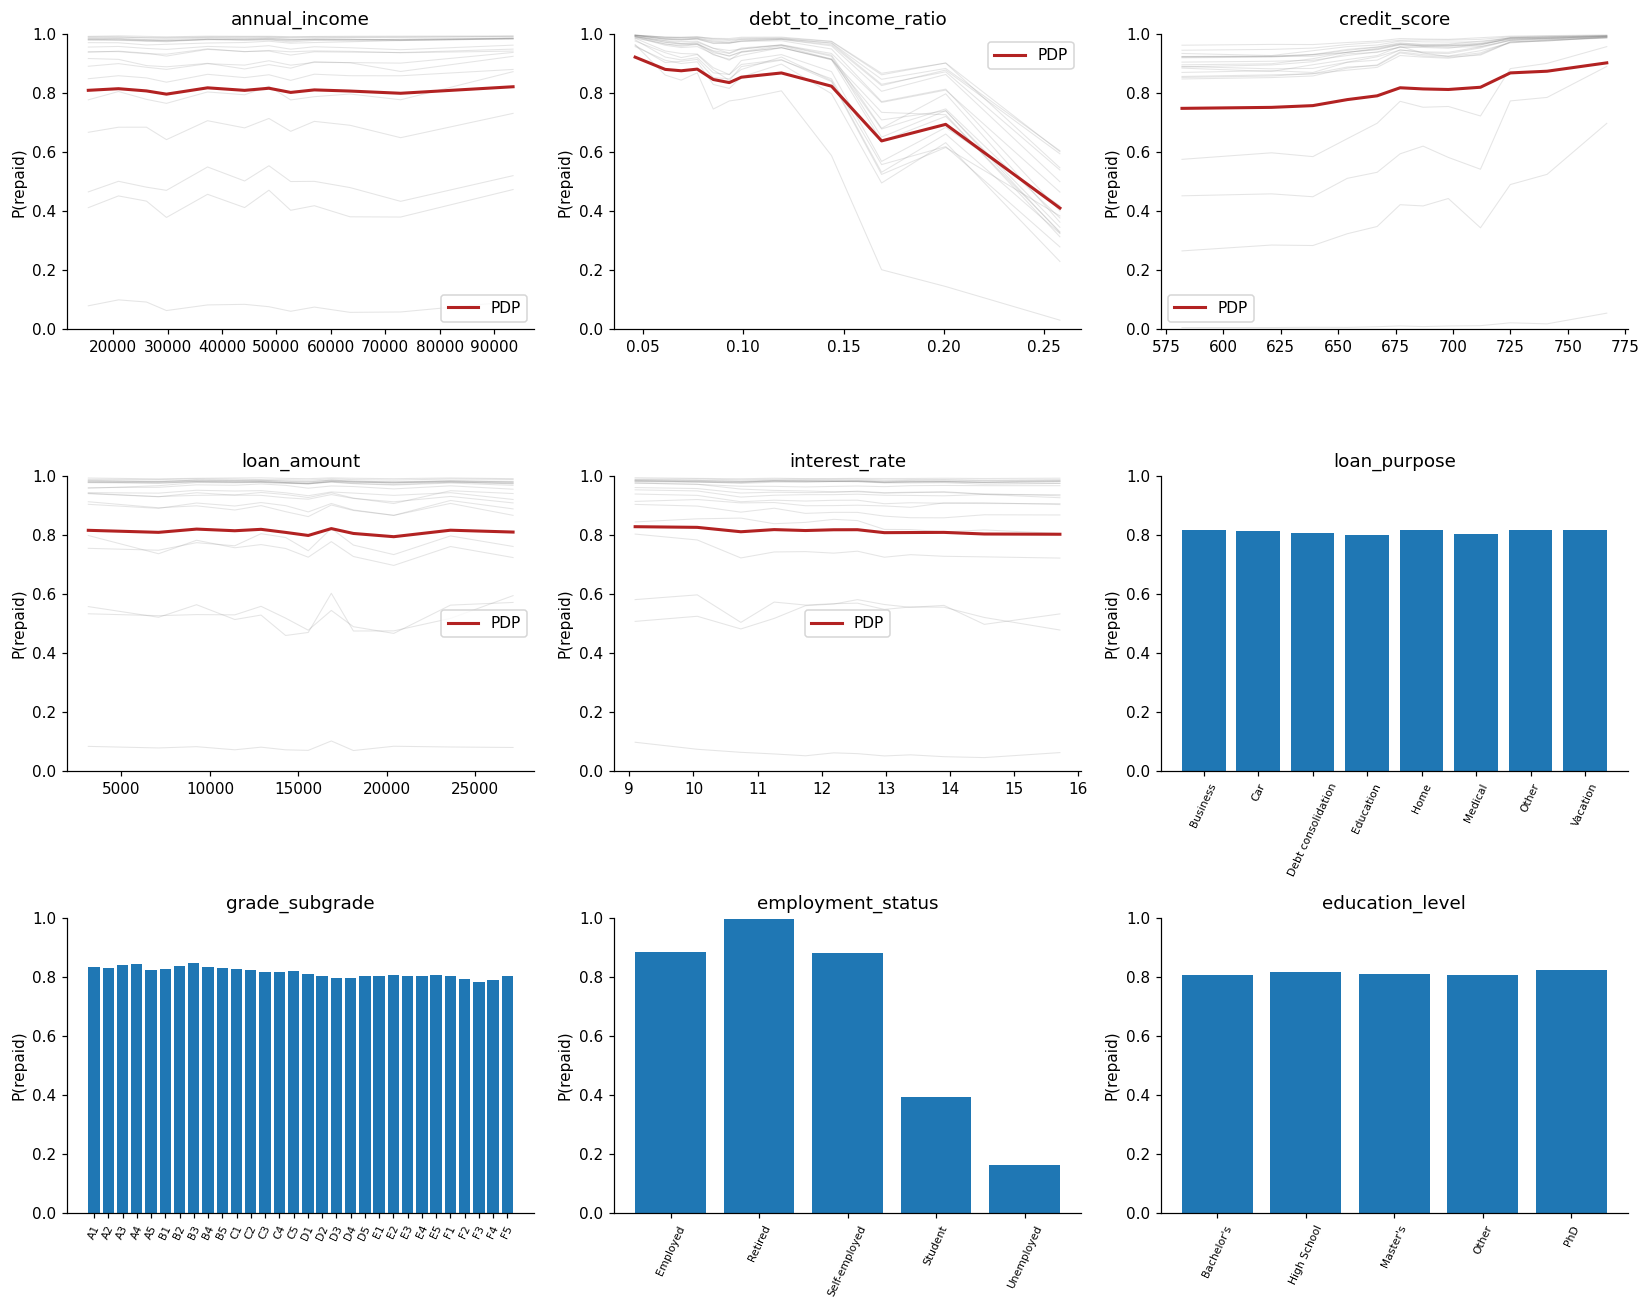

,Feature,Value,PDP_repaid
0,annual_income,15441.665,0.809821
1,annual_income,20987.88,0.815311
2,annual_income,26131.37,0.807765
3,annual_income,29803.85,0.796851
4,annual_income,37356.75,0.818259
...,...,...,...
103,education_level,Bachelor's,0.807013
104,education_level,High School,0.815573
105,education_level,Master's,0.809998
106,education_level,Other,0.807175


In [7]:
fit42,es42,thr42=splits[SEED]
def feature_grid(col):
    return sorted(fit42[col].unique()) if col in CAT else np.unique(np.quantile(fit42[col],np.linspace(.05,.95,GRID_SIZE)))

pdp_rows=[]
fig,axes=plt.subplots(3,3,figsize=(15,12))
for col,ax in zip(FEATURES,axes.ravel()):
    grid=feature_grid(col); curves=[]
    for v in grid:
        changed=explain_df.copy();changed[col]=v
        curves.append(predict(baseline,changed))
    curves=np.asarray(curves)
    for v,values in zip(grid,curves):
        pdp_rows.append({"Feature":col,"Value":v,"PDP_repaid":values.mean()})
    if col in CAT:
        ax.bar(range(len(grid)),curves.mean(axis=1));ax.set_xticks(range(len(grid)),grid,rotation=65,fontsize=7)
    else:
        ax.plot(grid,curves[:,:min(20,len(explain_df))],c="grey",alpha=.2,lw=.7)
        ax.plot(grid,curves.mean(axis=1),c="firebrick",lw=2,label="PDP");ax.legend()
    ax.set_title(col);ax.set_ylabel("P(repaid)");ax.set_ylim(0,1)
figure("pdp_ice")
table("pdp_values",pdp_rows,False)

## 7. Three Customer Cases and Local LIME Approximations
p.41 (19) calls for explanations of individual decisions. The cases cover low repayment probability, high repayment probability, and the observation closest to the threshold.
Each case includes the original inputs, predicted probability, threshold, decision, SHAP contributions, and the English narrative output.

**LIME implementation**: numerical perturbations use training statistics; categorical perturbations use empirical category distributions. Categories are represented by indicators of whether they match the current customer, and continuous features by standardized local changes. A distance-kernel-weighted Ridge model approximates the blackbox probability.
This is a transparent local-surrogate implementation of LIME, not the official lime package's default discretization configuration. It reports R² on independent perturbations and the error at the original observation. Do not treat a low-fidelity surrogate explanation as a fact about the model. LIME probability coefficients and SHAP log-odds contributions cannot be directly compared as ratios.

,id,P_repaid,Threshold,Decision,LIME_holdout_R2,LIME_at_instance,LIME_point_error,annual_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate,loan_purpose,grade_subgrade,employment_status,education_level
0,351822,0.000636,0.84,Reject,0.744709,0.008143,0.007506,37438.05,0.217,637,11750.19,14.93,Debt consolidation,D3,Unemployed,Other


Customer 351822: repayment probability 0.1%, threshold 84.0%, Reject. Main contributions: employment_status=Unemployed decreases repayment tendency; debt_to_income_ratio=0.217 decreases repayment tendency; credit_score=637 decreases repayment tendency.
LIME independent-perturbation R²=0.745, error at original observation=0.0075; explains model behavior only.


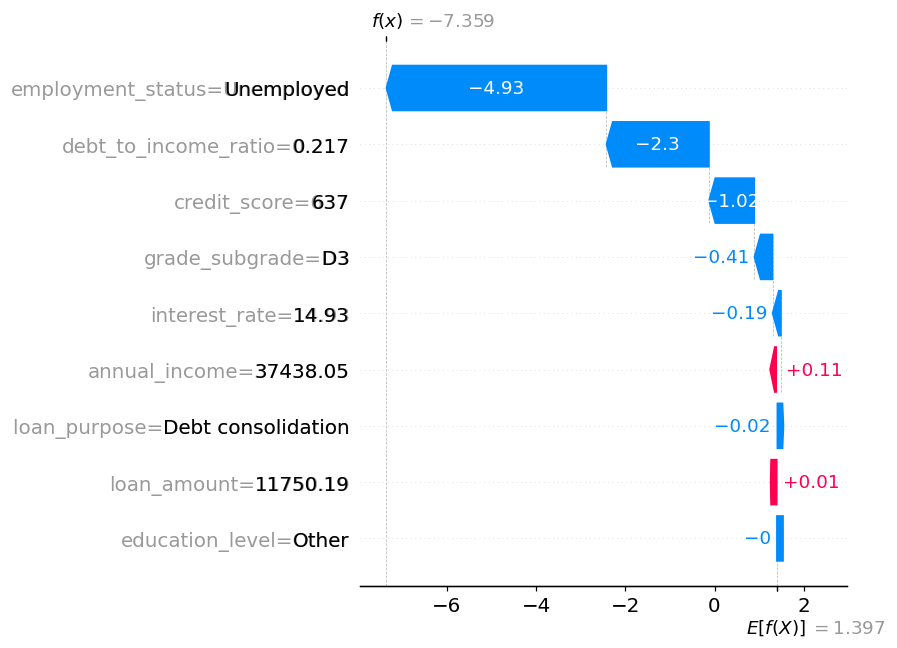

,id,P_repaid,Threshold,Decision,LIME_holdout_R2,LIME_at_instance,LIME_point_error,annual_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate,loan_purpose,grade_subgrade,employment_status,education_level
0,231848,0.999897,0.84,Approve,0.062533,1.011979,0.012083,39473.4,0.041,784,12409.92,9.97,Education,B2,Retired,Bachelor's


Customer 231848: repayment probability 100.0%, threshold 84.0%, Approve. Main contributions: employment_status=Retired increases repayment tendency; credit_score=784 increases repayment tendency; debt_to_income_ratio=0.041 increases repayment tendency.
LIME independent-perturbation R²=0.063, error at original observation=0.0121; explains model behavior only.


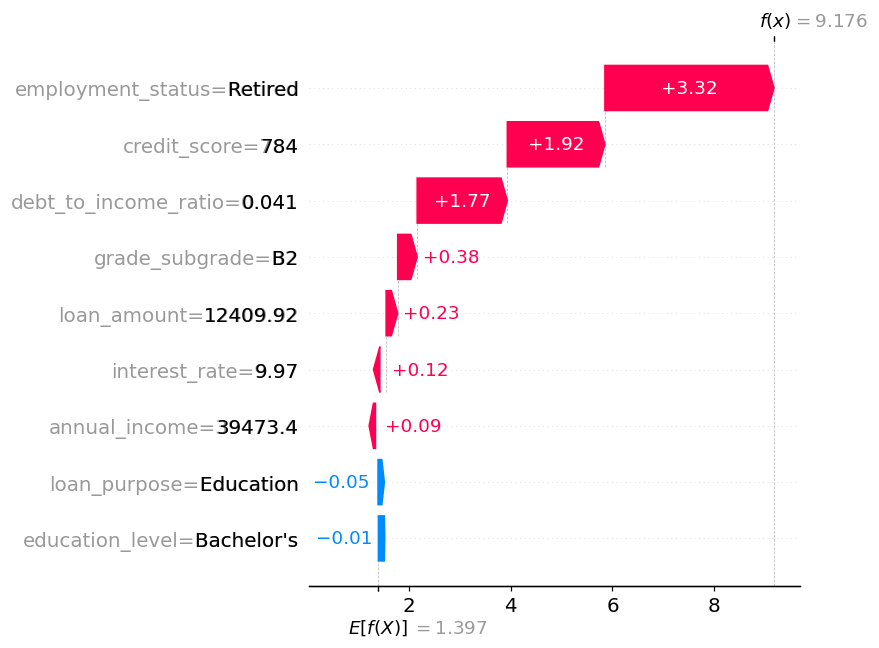

,id,P_repaid,Threshold,Decision,LIME_holdout_R2,LIME_at_instance,LIME_point_error,annual_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate,loan_purpose,grade_subgrade,employment_status,education_level
0,125692,0.840011,0.84,Approve,0.087655,0.829197,0.010814,15703.37,0.072,467,4582.07,15.99,Medical,F3,Self-employed,Bachelor's


Customer 125692: repayment probability 84.0%, threshold 84.0%, Approve. Main contributions: credit_score=467 decreases repayment tendency; debt_to_income_ratio=0.072 increases repayment tendency; employment_status=Self-employed increases repayment tendency.
LIME independent-perturbation R²=0.088, error at original observation=0.0108; explains model behavior only.


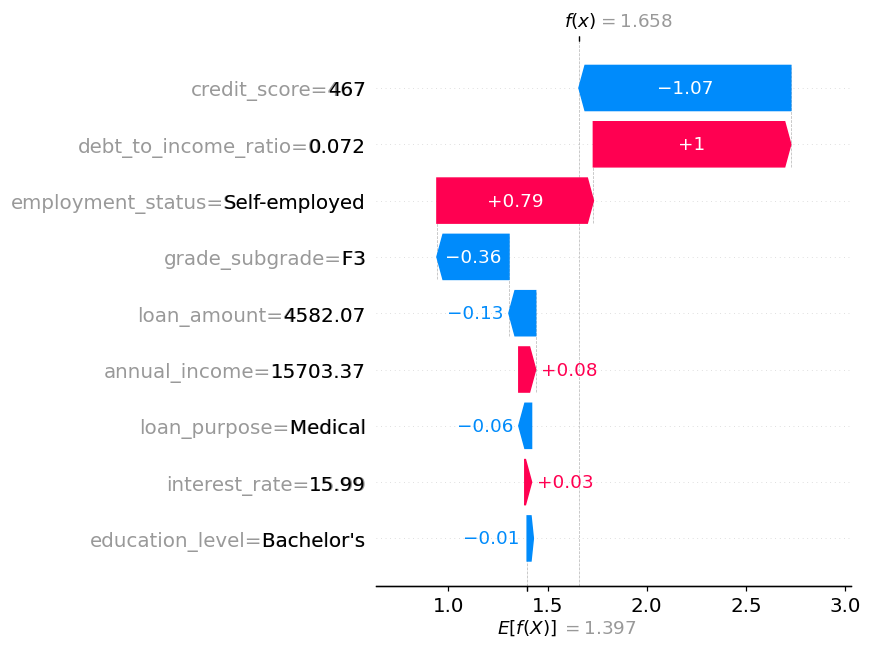

,Feature,Value,SHAP_logodds,LIME_coefficient,id
0,annual_income,37438.05,0.105932,0.000463,351822
1,debt_to_income_ratio,0.217,-2.300270,-0.123817,351822
2,credit_score,637,-1.016432,0.067333,351822
3,loan_amount,11750.19,0.010619,0.001408,351822
4,interest_rate,14.93,-0.190312,-0.016347,351822
5,loan_purpose,Debt consolidation,-0.022659,-0.014091,351822
6,grade_subgrade,D3,-0.408215,-0.017796,351822
7,employment_status,Unemployed,-4.934159,-0.637042,351822
8,education_level,Other,-0.000586,0.011375,351822
9,annual_income,39473.4,0.085732,0.000628,231848


In [8]:
case_pos=list(dict.fromkeys([int(np.argmin(p_comp)),int(np.argmax(p_comp)),
                            int(np.argmin(abs(p_comp-baseline["threshold"])))]))
cases=comparison.iloc[case_pos].copy()
case_contrib,case_base=contributions(baseline,cases)
def lime_local(bundle,row,seed):
    rng=np.random.default_rng(seed); features=bundle["features"]
    scales=fit42[NUM].std().replace(0,1)
    def neighborhood(n):
        raw=pd.concat([row.to_frame().T]*n,ignore_index=True)
        z=np.zeros((n,len(features)))
        for j,c in enumerate(features):
            if c in CAT:
                raw[c]=rng.choice(fit42[c].to_numpy(),n,replace=True)
                z[:,j]=(raw[c].to_numpy()==row[c]).astype(float)
            else:
                vals=rng.normal(float(row[c]),float(scales[c]),n)
                vals=np.clip(vals,float(fit42[c].min()),float(fit42[c].max()))
                raw[c]=vals;z[:,j]=(vals-float(row[c]))/float(scales[c])
        center=np.array([1. if c in CAT else 0. for c in features])
        distance=np.linalg.norm(z-center,axis=1)
        weights=np.exp(-distance**2/(.75*np.sqrt(len(features)))**2)
        return raw,z,weights,center
    raw,z,w,center=neighborhood(LIME_N)
    raw.iloc[0]=row;z[0]=center;w[0]=1
    target=predict(bundle,raw)
    surrogate=Ridge(alpha=1.).fit(z,target,sample_weight=w)
    vr,vz,vw,_=neighborhood(max(200,LIME_N//3));vy=predict(bundle,vr)
    vp=surrogate.predict(vz);denom=np.sum(vw*(vy-np.average(vy,weights=vw))**2)
    r2=1-np.sum(vw*(vy-vp)**2)/denom if denom>0 else np.nan
    local_p=float(surrogate.predict(center[None,:])[0]); true_p=float(predict(bundle,row.to_frame().T)[0])
    return surrogate.coef_,r2,local_p,true_p

case_rows=[];local_rows=[]
for i,(_,row) in enumerate(cases.iterrows()):
    p=float(predict(baseline,row.to_frame().T)[0]);t=baseline["threshold"]
    lime_coef,r2,lp,_=lime_local(baseline,row,SEED+i)
    record={ID:row[ID],"P_repaid":p,"Threshold":t,"Decision":"Approve" if p>=t else "Reject",
            "LIME_holdout_R2":r2,"LIME_at_instance":lp,"LIME_point_error":abs(lp-p),**row[FEATURES].to_dict()}
    case_rows.append(record)
    rank=pd.DataFrame({"Feature":FEATURES,"Value":[row[c] for c in FEATURES],
                       "SHAP_logodds":case_contrib[i],"LIME_coefficient":lime_coef})
    rank[ID]=row[ID];local_rows.extend(rank.to_dict("records"))
    display(pd.DataFrame([record]))
    top=rank.iloc[np.argsort(-abs(rank.SHAP_logodds.to_numpy()))[:3]]
    explanation="; ".join(f"{r.Feature}={r.Value} {'increases' if r.SHAP_logodds>0 else 'decreases'} repayment tendency" for r in top.itertuples())
    print(f"Customer {row[ID]}: repayment probability {p:.1%}, threshold {t:.1%}, {'Approve' if p>=t else 'Reject'}. Main contributions: {explanation}.")
    print(f"LIME independent-perturbation R²={r2:.3f}, error at original observation={abs(lp-p):.4f}; explains model behavior only.")
    shap.plots.waterfall(shap.Explanation(values=case_contrib[i],base_values=float(case_base[i]),
        feature_names=[f"{c}={row[c]}" for c in FEATURES]),show=False,max_display=10)
    figure(f"case_{row[ID]}_waterfall")
table("customer_cases",case_rows,False)
table("customer_local_explanations",local_rows,False)

## 8. XPER: Shapley Decomposition of AUC and Economic Performance
Course pp.197–208 (164–175). Method reference: [original XPER paper](https://arxiv.org/html/2212.05866v2).
For coalition S, retain the customer's X_S and jointly sample the remaining columns from a background row, breaking their alignment with Y.
The value v(S) is obtained by **computing performance for each perturbation and then averaging those performance values**, not by averaging probabilities before computing AUC.
All 512 coalitions of the nine features are enumerated, so the Shapley weighted sum is exact; the background integral remains a Monte Carlo approximation.
The economic version holds actual loan amounts and interest rates fixed as the contractual payoff context. Only model inputs are perturbed; the realized contracts are unchanged. It is therefore an economic XPER extension for this fixed-contract setting, not a causal estimate of the profit from changing a contract.
The baseline is the randomized performance of the empty coalition. Its finite-sample AUC is not guaranteed to equal exactly 0.5.

XPER coalition 0 / 512
XPER coalition 64 / 512
XPER coalition 128 / 512
XPER coalition 192 / 512
XPER coalition 256 / 512
XPER coalition 320 / 512
XPER coalition 384 / 512
XPER coalition 448 / 512


,Metric,Feature,Contribution,MC_SE
0,AUC,annual_income,0.004775,0.001018
1,AUC,debt_to_income_ratio,0.111138,0.001926
2,AUC,credit_score,0.069294,0.003450
3,AUC,loan_amount,0.003859,0.001016
4,AUC,interest_rate,0.003135,0.000581
5,AUC,loan_purpose,-0.000587,0.000423
6,AUC,grade_subgrade,0.015037,0.001354
7,AUC,employment_status,0.195088,0.004927
8,AUC,education_level,0.000703,0.000403
9,PNL_per_applicant,annual_income,-0.822270,3.274123


,Metric,Empty_baseline,Sum_contributions,Full_value
0,AUC,0.493539,0.402442,0.895981
1,PNL_per_applicant,-277.483019,989.729690,712.246672


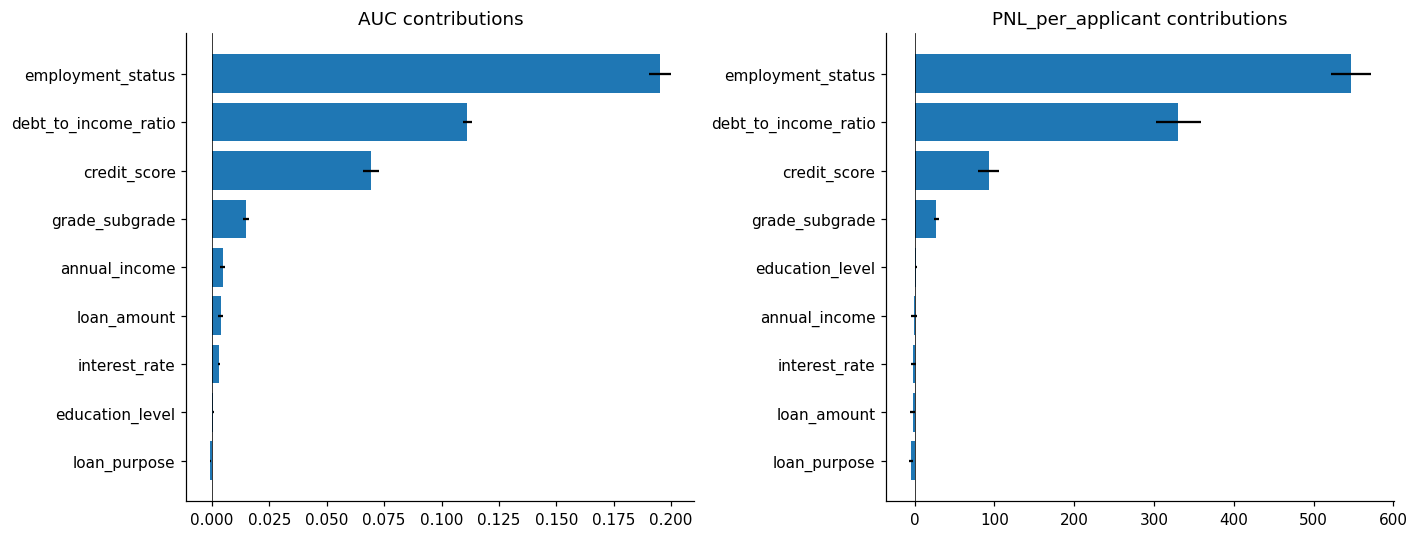

Error bars show Monte Carlo SE from background randomization only, not sampling confidence intervals for the customer population.


In [9]:
def xper_decompose(bundle,df,background,draws,seed):
    d=len(bundle["features"]);rng=np.random.default_rng(seed)
    donor_positions=rng.integers(0,len(background),size=(draws,len(df)))
    values=np.zeros((1<<d,draws,2))
    for mask in range(1<<d):
        if mask%64==0:print("XPER coalition",mask,"/",1<<d,flush=True)
        for r in range(draws):
            hybrid=df.copy()
            donors=background.iloc[donor_positions[r]]
            for j,c in enumerate(bundle["features"]):
                if not (mask>>j)&1:hybrid[c]=donors[c].to_numpy()
            p=predict(bundle,hybrid)
            values[mask,r]=[roc_auc_score(df[TARGET],p),profits(df,p>=bundle["threshold"]).mean()]
    phi=np.zeros((d,draws,2))
    for j in range(d):
        for mask in range(1<<d):
            if not (mask>>j)&1:
                weight=1/(d*comb(d-1,mask.bit_count()))
                phi[j]+=weight*(values[mask|(1<<j)]-values[mask])
    np.testing.assert_allclose(values[0]+phi.sum(axis=0),values[-1],rtol=1e-9,atol=1e-8)
    rows=[]
    for k,metric in enumerate(["AUC","PNL_per_applicant"]):
        for j,c in enumerate(bundle["features"]):
            rows.append({"Metric":metric,"Feature":c,"Contribution":phi[j,:,k].mean(),
                         "MC_SE":phi[j,:,k].std(ddof=1)/np.sqrt(draws)})
    summary=pd.DataFrame({"Metric":["AUC","PNL_per_applicant"],"Empty_baseline":values[0].mean(axis=0),
                          "Sum_contributions":phi.mean(axis=1).sum(axis=0),"Full_value":values[-1].mean(axis=0)})
    return pd.DataFrame(rows),summary

xper_sample,_=train_test_split(comparison,train_size=min(XPER_N,len(comparison)-1),
                              stratify=comparison[TARGET],random_state=SEED)
xper_values,xper_summary=xper_decompose(baseline,xper_sample,fit42,XPER_DRAWS,SEED)
table("xper_values",xper_values);table("xper_additivity",xper_summary)
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,(metric,g) in zip(axes,xper_values.groupby("Metric",sort=False)):
    g=g.sort_values("Contribution");ax.barh(g.Feature,g.Contribution,xerr=g.MC_SE)
    ax.set_title(metric+" contributions");ax.axvline(0,c="black",lw=.5)
figure("xper_contributions")
print("Error bars show Monte Carlo SE from background randomization only, not sampling confidence intervals for the customer population.")

## 9. Explanation Stability, Decision Consistency, and Input Noise
p.227 (193): compare ||phi(f1)-phi(f2)||_2 using the same features and observations.
SHAP baselines/training paths may differ across models. The reported explanation stability is specific to the native TreeSHAP definition used here.
Also calculate normalized importance distances, rank correlations, customer-level contribution distances, and decision-flip rates under a fixed threshold and each model's own threshold.

,Family,Seed_A,Seed_B,Importance_L2,Normalized_L2,Rank_Spearman,Mean_local_L2,Top3_overlap,Mean_abs_probability_change,Fixed_threshold_flip,Own_threshold_flip
0,baseline,1,10,0.024649,0.007619,1.000000,0.168474,1.0,0.011976,0.037,0.051
1,baseline,1,42,0.018622,0.006639,1.000000,0.157956,1.0,0.010955,0.028,0.044
2,baseline,1,100,0.023029,0.005811,1.000000,0.151521,1.0,0.011203,0.030,0.034
3,baseline,1,2026,0.023939,0.006795,0.983333,0.153739,1.0,0.011436,0.028,0.026
4,baseline,10,42,0.015409,0.003221,1.000000,0.173963,1.0,0.011799,0.025,0.025
5,baseline,10,100,0.033789,0.008583,1.000000,0.170834,1.0,0.012098,0.035,0.033
6,baseline,10,2026,0.036266,0.011151,0.983333,0.177192,1.0,0.013182,0.035,0.045
7,baseline,42,100,0.025323,0.007895,1.000000,0.162114,1.0,0.011911,0.032,0.024
8,baseline,42,2026,0.029203,0.008951,0.983333,0.164668,1.0,0.013083,0.032,0.046
9,baseline,100,2026,0.041000,0.010783,0.983333,0.169723,1.0,0.012398,0.036,0.034


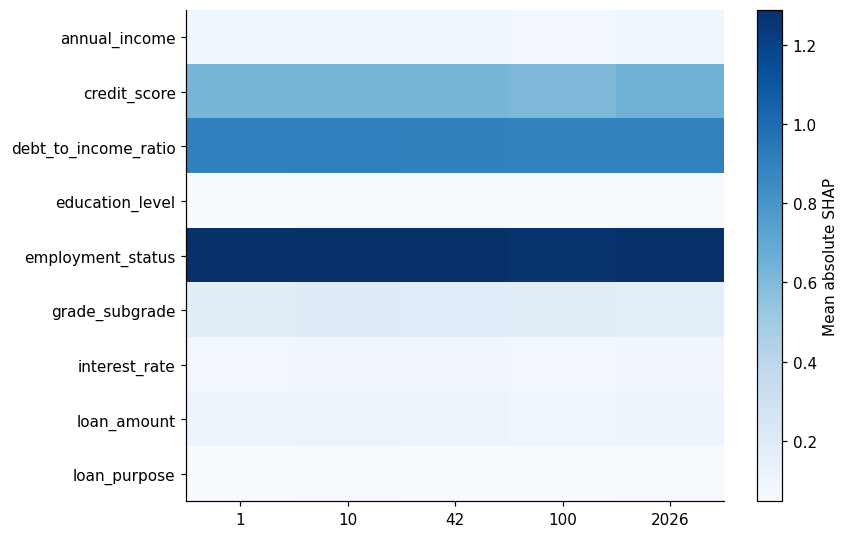

,Noise_SD_fraction,AUC_clean,AUC_noisy,Mean_abs_change,Decision_flip
0,0.05,0.911272,0.89814,0.028077,0.064


,Noise_SD_fraction,AUC_clean,AUC_noisy,Mean_abs_change,Decision_flip
0,0.05,0.911272,0.89814,0.028077,0.064


In [10]:
def stability_report(bundles,label):
    attrs={};preds={};global_rows=[]
    for s,b in bundles.items():
        vals,_=contributions(b,explain_df);attrs[s]=vals;preds[s]=predict(b,explain_df)
        for c,v in zip(FEATURES,np.abs(vals).mean(axis=0)):
            global_rows.append({"Family":label,"Seed":s,"Feature":c,"Mean_abs_SHAP":v})
    rows=[]
    for a,b in combinations(bundles,2):
        ga,gb=np.abs(attrs[a]).mean(axis=0),np.abs(attrs[b]).mean(axis=0)
        na,nb=ga/max(ga.sum(),1e-12),gb/max(gb.sum(),1e-12)
        rows.append({"Family":label,"Seed_A":a,"Seed_B":b,
            "Importance_L2":np.linalg.norm(ga-gb),"Normalized_L2":np.linalg.norm(na-nb),
            "Rank_Spearman":spearmanr(ga,gb).statistic,
            "Mean_local_L2":np.linalg.norm(attrs[a]-attrs[b],axis=1).mean(),
            "Top3_overlap":len(set(np.argsort(-ga)[:3])&set(np.argsort(-gb)[:3]))/3,
            "Mean_abs_probability_change":abs(preds[a]-preds[b]).mean(),
            "Fixed_threshold_flip":np.mean((preds[a]>=baseline["threshold"])!=(preds[b]>=baseline["threshold"])),
            "Own_threshold_flip":np.mean((preds[a]>=bundles[a]["threshold"])!=(preds[b]>=bundles[b]["threshold"]))})
    return pd.DataFrame(rows),pd.DataFrame(global_rows)

stability,importance_seeds=stability_report(models,"baseline")
table("explanation_stability",stability)
table("importance_by_seed",importance_seeds,False)
heat=importance_seeds.pivot(index="Feature",columns="Seed",values="Mean_abs_SHAP")
plt.figure(figsize=(8,5));plt.imshow(heat,aspect="auto",cmap="Blues")
plt.yticks(range(len(heat)),heat.index);plt.xticks(range(len(heat.columns)),heat.columns)
plt.colorbar(label="Mean absolute SHAP");figure("importance_stability_heatmap")
rng=np.random.default_rng(SEED);noisy=explain_df.copy()
for c in NUM:
    noisy[c]=np.clip(noisy[c]+rng.normal(0,.05*fit42[c].std(),len(noisy)),fit42[c].min(),fit42[c].max())
clean_p,noisy_p=predict(baseline,explain_df),predict(baseline,noisy)
table("input_noise",[{"Noise_SD_fraction":.05,"AUC_clean":roc_auc_score(explain_df[TARGET],clean_p),
    "AUC_noisy":roc_auc_score(explain_df[TARGET],noisy_p),"Mean_abs_change":abs(clean_p-noisy_p).mean(),
    "Decision_flip":np.mean((clean_p>=baseline["threshold"])!=(noisy_p>=baseline["threshold"]))}])

## 11. FPDP and Candidate Variables: What May Drive Disparities?
pp.287, 290–291 (250, 253–254): set one feature to a common value and recompute the fairness statistic, while retaining the other inputs and original group membership. If the original test rejects but at least one grid point does not, flag the feature as an exploratory candidate.
Failure to reject does not prove fairness. Grid searches involve multiple attempts, so candidate screening is not a formal causal test.
Exclude degenerate cases in which everyone is approved or rejected. Mark the all-group chi-square test as not assessable when expected cell counts are sparse.

,Feature,Attribute,Original_p,Grid_assessed,Candidate_exploratory,Max_grid_p
0,annual_income,gender,0.568894,12,False,0.448508
1,annual_income,marital_status,0.881405,12,False,0.989184
2,credit_score,gender,0.568894,11,False,0.648374
3,credit_score,marital_status,0.881405,12,False,0.772892
4,debt_to_income_ratio,gender,0.568894,6,False,0.838865
5,debt_to_income_ratio,marital_status,0.881405,11,False,0.662568
6,education_level,gender,0.568894,5,False,0.723788
7,education_level,marital_status,0.881405,5,False,0.898212
8,employment_status,gender,0.568894,2,False,0.835103
9,employment_status,marital_status,0.881405,3,False,0.810778


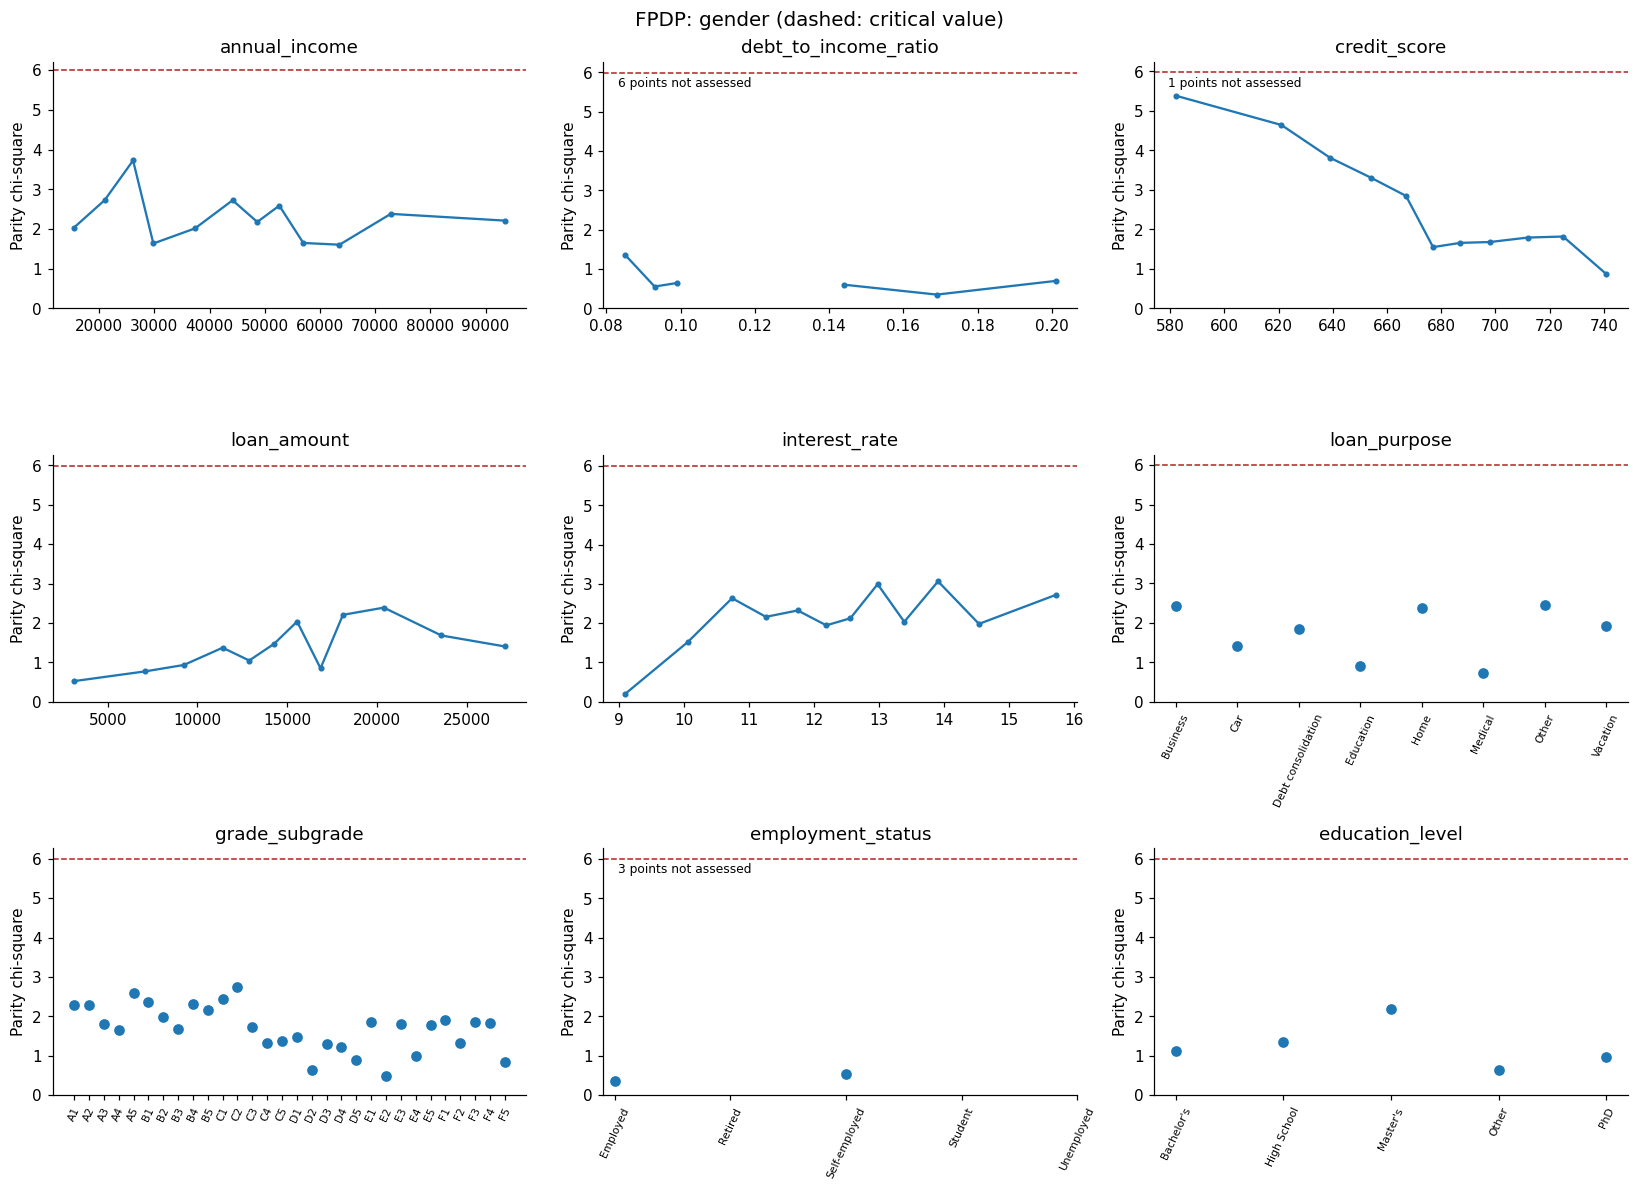

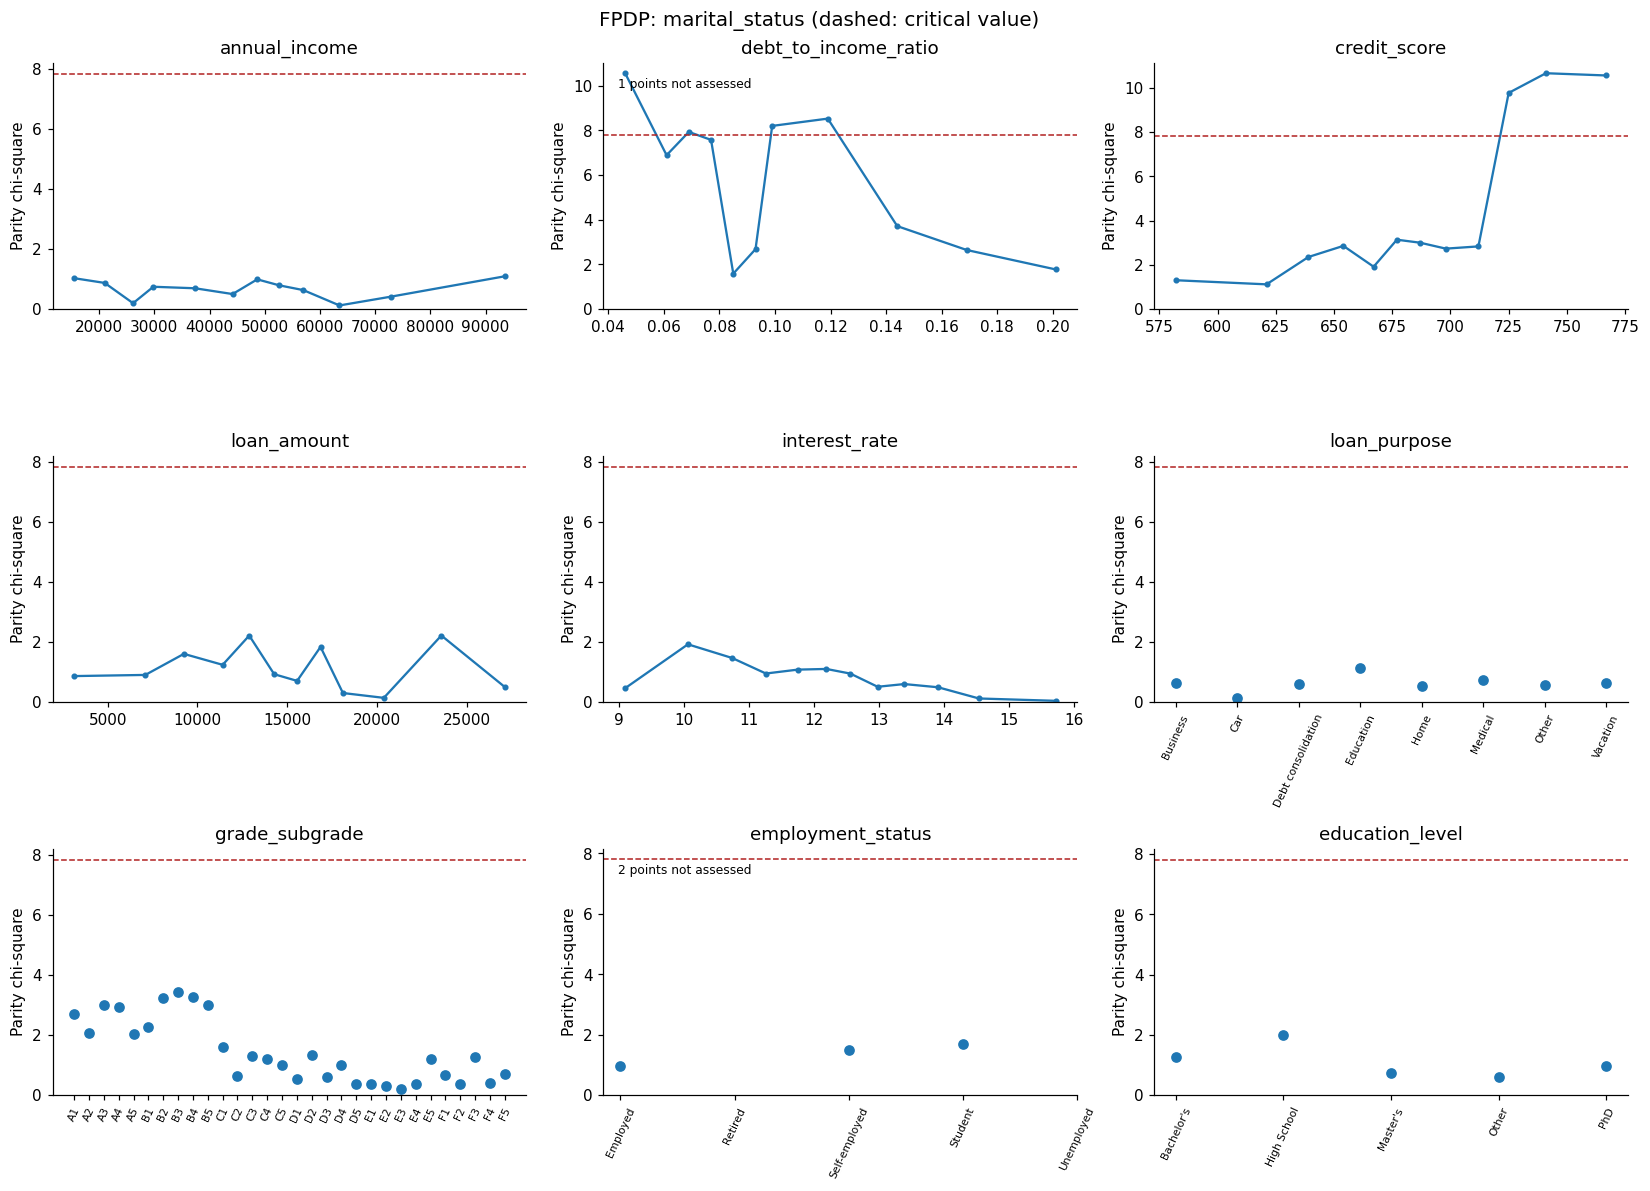

In [11]:
def independence_stat(group,decision):
    ct=pd.crosstab(np.asarray(group),np.asarray(decision)).reindex(columns=[False,True],fill_value=0)
    if ct.shape[0]<2 or (ct.sum(axis=0)==0).any():
        return {"Chi2":0.,"p":np.nan,"critical":np.nan,"valid":False}
    stat,pv,dof,expected=chi2_contingency(ct,correction=False)
    valid=bool(np.all(expected>=5))
    return {"Chi2":float(stat),"p":float(pv) if valid else np.nan,
            "critical":float(chi2.ppf(1-ALPHA,dof)),"valid":valid}

fpdp_df=comparison.sample(min(FPDP_N,len(comparison)),random_state=SEED)
base_dec=predict(baseline,fpdp_df)>=baseline["threshold"]
original_stats={a:independence_stat(fpdp_df[a],base_dec) for a in AUDIT}
fpdp_rows=[]
for c in FEATURES:
    for value in feature_grid(c):
        changed=fpdp_df.copy();changed[c]=value
        decision=predict(baseline,changed)>=baseline["threshold"]
        for attr in AUDIT:
            stat=independence_stat(fpdp_df[attr],decision)  # D retains original group membership; never overwrite it with the substituted feature value.
            rates=pd.DataFrame({"D":fpdp_df[attr].to_numpy(),"A":decision}).groupby("D").A.mean()
            fpdp_rows.append({"Feature":c,"Value":str(value),"Attribute":attr,
                "Approval":decision.mean(),"Approval_gap":rates.max()-rates.min(),**stat})
fpdp=pd.DataFrame(fpdp_rows);table("fpdp_grid",fpdp,False)
candidate_rows=[]
for (c,attr),g in fpdp.groupby(["Feature","Attribute"]):
    eligible=g[g.valid & g.Approval.between(.05,.95)]
    candidate_rows.append({"Feature":c,"Attribute":attr,"Original_p":original_stats[attr]["p"],
        "Grid_assessed":len(eligible),"Candidate_exploratory":bool(original_stats[attr]["p"]<ALPHA and
                    (eligible.p>=ALPHA).any()),"Max_grid_p":eligible.p.max()})
candidates=table("fpdp_candidates",candidate_rows)
# Keep each feature's numerical/categorical coordinates; do not depict sparse or degenerate points as zero statistics implying fairness.
for attr in AUDIT:
    fig,axes=plt.subplots(3,3,figsize=(15,11))
    for c,ax in zip(FEATURES,axes.ravel()):
        g=fpdp[(fpdp.Attribute==attr)&(fpdp.Feature==c)]
        valid=g.valid & g.Approval.between(.05,.95)
        ys=np.where(valid,g.Chi2,np.nan)
        if c in CAT:
            xs=np.arange(len(g));ax.scatter(xs,ys)
            ax.set_xticks(xs,g.Value,rotation=65,fontsize=7)
        else:
            xs=g.Value.astype(float).to_numpy();ax.plot(xs,ys,"o-",ms=3)
        if np.isfinite(original_stats[attr]["critical"]):
            ax.axhline(original_stats[attr]["critical"],ls="--",c="firebrick",lw=1)
        if not valid.all():
            ax.text(.03,.94,f"{int((~valid).sum())} points not assessed",transform=ax.transAxes,
                    va="top",fontsize=8)
        ax.set_title(c);ax.set_ylabel("Parity chi-square");ax.set_ylim(bottom=0)
    fig.suptitle("FPDP: "+attr+" (dashed: critical value)",fontsize=13)
    figure("fpdp_"+attr)

## 12. Feature Associations with Groups and Outcomes
pp.296–297 (259–260): examine both X-D and X-Y associations, not only associations with sensitive attributes.
Use Cramér's V for categorical features and eta-squared for numerical features. These statistics have different definitions and are plotted separately.
A sensitive attribute's association with itself represents a direct input, not a proxy. Neither association measures nor FPDP establish causality.

,Feature,Attribute,Measure,X_D,X_Y,Candidate_exploratory
0,annual_income,gender,Eta_squared,0.000019,0.000049,False
1,debt_to_income_ratio,gender,Eta_squared,0.000016,0.112637,False
2,credit_score,gender,Eta_squared,0.000055,0.054903,False
3,loan_amount,gender,Eta_squared,0.000008,0.000024,False
4,interest_rate,gender,Eta_squared,0.000018,0.017507,False
5,loan_purpose,gender,Cramers_V,0.008699,0.026559,False
6,grade_subgrade,gender,Cramers_V,0.011742,0.228022,False
7,employment_status,gender,Cramers_V,0.004216,0.658249,False
8,education_level,gender,Cramers_V,0.006208,0.025721,False
9,annual_income,marital_status,Eta_squared,0.000097,0.000049,False


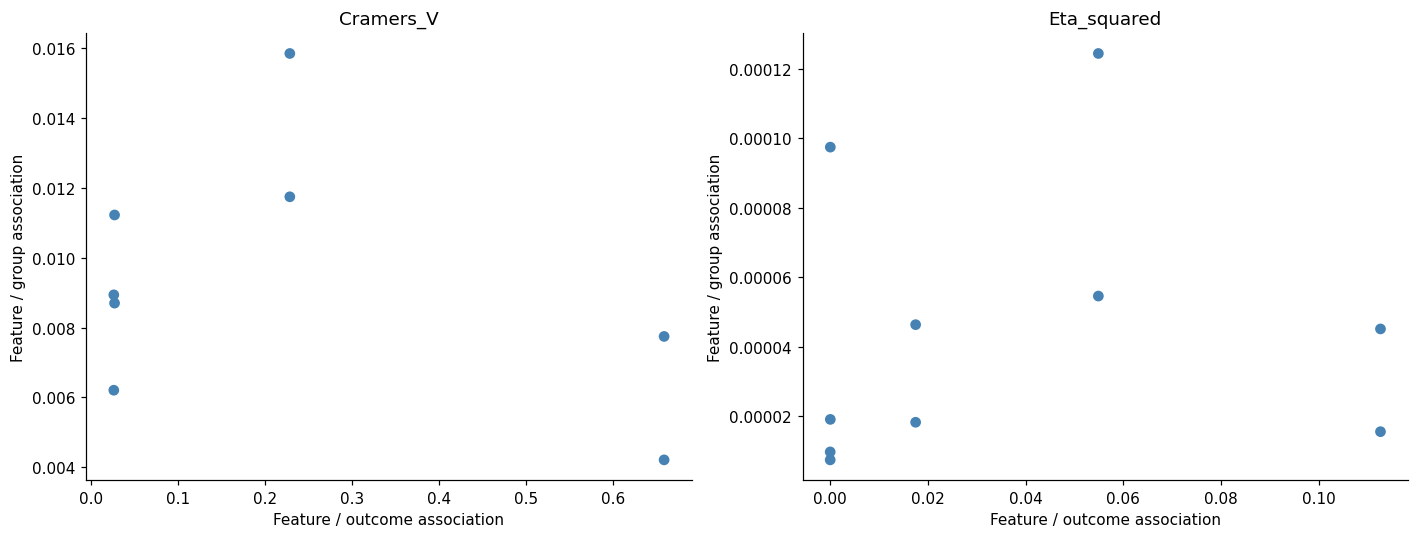

In [12]:
def association(feature,group,is_category):
    if is_category:
        ct=pd.crosstab(feature,group)
        if min(ct.shape)<2:return np.nan
        stat=chi2_contingency(ct,correction=False)[0]
        return np.sqrt(stat/(ct.to_numpy().sum()*(min(ct.shape)-1)))
    data=pd.DataFrame({"x":np.asarray(feature,float),"g":np.asarray(group)})
    ss=((data.x-data.x.mean())**2).sum()
    return sum(len(g)*(g.x.mean()-data.x.mean())**2 for _,g in data.groupby("g"))/ss if ss else np.nan

assoc=[]
for attr in AUDIT:
    for c in FEATURES:
        if c==attr:continue
        flag=c in CAT
        assoc.append({"Feature":c,"Attribute":attr,"Measure":"Cramers_V" if flag else "Eta_squared",
            "X_D":association(fit42[c],fit42[attr],flag),"X_Y":association(fit42[c],fit42[TARGET],flag)})
assoc=pd.DataFrame(assoc).merge(candidates[["Feature","Attribute","Candidate_exploratory"]],how="left")
table("candidate_associations",assoc)
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,(measure,g) in zip(axes,assoc.groupby("Measure")):
    ax.scatter(g.X_Y,g.X_D,c=np.where(g.Candidate_exploratory,"firebrick","steelblue"))
    for r in g.itertuples():
        if r.Candidate_exploratory:ax.annotate(r.Feature+"/"+r.Attribute,(r.X_Y,r.X_D),fontsize=6)
    ax.set_title(measure);ax.set_xlabel("Feature / outcome association");ax.set_ylabel("Feature / group association")
figure("candidate_associations")

## 14. Fairness-Mitigation Experiments and a Predefined Selection Rule
pp.271, 298–299 (235, 261–262): compare fairness improvements with predictive and economic costs.
Using identical fit/es/threshold/comparison rows, compare the original nine features, removal of employment, removal of education, removal of both, gender×Y training-sample reweighting, and the stability constraint above. Sensitive attributes are not used to set group-specific approval thresholds.
Reweighting uses P(D)P(Y)/P(D,Y), estimated from fit data only. It does not guarantee improvements for every group or fairness metric.

The selection rule is fixed in advance: an AUC loss of at most 0.01, a positive-P&L loss of at most 5%, a smaller maximum approval-rate gap across the four attributes than the baseline, and no increase in the maximum EO gap. Among eligible candidates, choose the smallest maximum approval-rate gap; otherwise retain the baseline.
This is a policy assumption for the classroom demonstration, not a universal definition of fairness. Selection uses comparison data only.

,Variant,N,AUC,AP_repaid,AP_default,Gini,KS,Brier,Accuracy,PNL,PNL_per_applicant,Approval,Default_among_approved,Threshold,Worst_DP_gap,Worst_EO_gap,Eligible
0,baseline,57399,0.920491,0.974680,0.831286,0.840983,0.680129,0.072263,0.837157,5.194254e+07,904.93815,0.704071,0.048351,0.84,0.033345,0.022812,False
1,gender_reweight,57399,0.920458,0.974679,0.831205,0.840916,0.680852,0.072303,0.837593,5.191244e+07,904.41371,0.705169,0.048745,0.84,0.027308,0.017221,True


Frozen approach: gender_reweight | Frozen threshold: 0.84


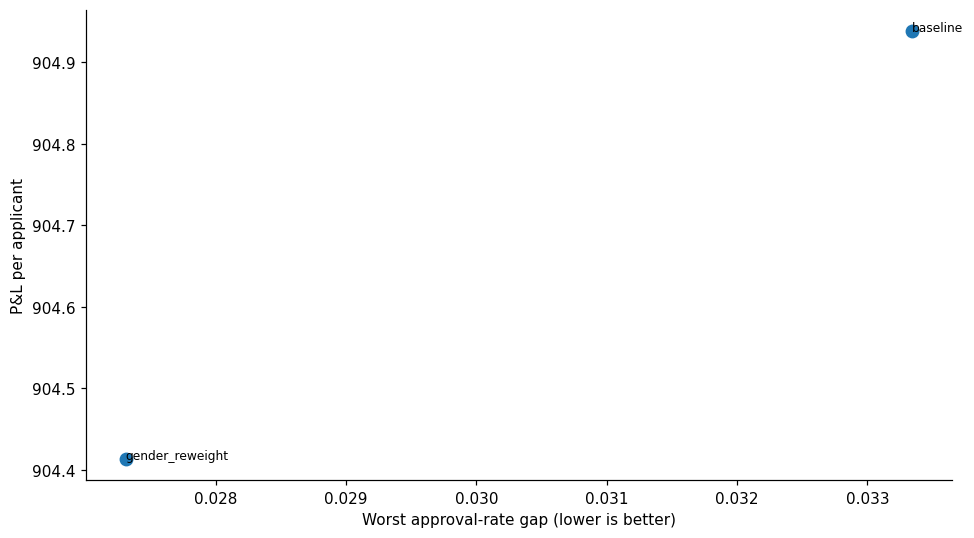

In [17]:
variants = {"baseline": baseline}

# Gender × Y reweighting
counts = fit42.groupby(["gender", TARGET]).size()
gd = fit42["gender"].value_counts(normalize=True)
yd = fit42[TARGET].value_counts(normalize=True)

weights = np.array([
    gd[g] * yd[y] / (counts.loc[(g, y)] / len(fit42))
    for g, y in zip(fit42["gender"], fit42[TARGET])
])

weights /= weights.mean()

variants["gender_reweight"] = fit_bundle(
    SEED,
    weight=weights
)

tradeoffs=[]
for name,bundle in variants.items():
    p=predict(bundle,comparison);detail=group_metrics(comparison,p,bundle["threshold"]);g=gaps(detail)
    tradeoffs.append({"Variant":name,**metrics(comparison,p,bundle["threshold"]),
                      "Worst_DP_gap":g.Approval_gap.max(),"Worst_EO_gap":g.EO_gap.max()})
    table("mitigation_"+name+"_groups",detail,False)
tradeoffs=pd.DataFrame(tradeoffs);base_row=tradeoffs.set_index("Variant").loc["baseline"]
tradeoffs["Eligible"]=(tradeoffs.AUC>=base_row.AUC-MAX_AUC_LOSS)&(
    tradeoffs.PNL>=base_row.PNL-MAX_PNL_LOSS*abs(base_row.PNL))&(
    tradeoffs.Worst_DP_gap<base_row.Worst_DP_gap-1e-6)&(
    tradeoffs.Worst_EO_gap<=base_row.Worst_EO_gap+1e-6)
eligible=tradeoffs[tradeoffs.Eligible].sort_values(["Worst_DP_gap","PNL"],ascending=[True,False])
SELECTED_NAME=str(eligible.iloc[0].Variant) if len(eligible) else "baseline"
selected=variants[SELECTED_NAME]
table("mitigation_tradeoffs",tradeoffs)
print("Frozen approach:",SELECTED_NAME,"| Frozen threshold:",selected["threshold"])
fig,ax=plt.subplots(figsize=(9,5))
ax.scatter(tradeoffs.Worst_DP_gap,tradeoffs.PNL_per_applicant,s=65)
for r in tradeoffs.itertuples():ax.annotate(r.Variant,(r.Worst_DP_gap,r.PNL_per_applicant),fontsize=8)
ax.set_xlabel("Worst approval-rate gap (lower is better)");ax.set_ylabel("P&L per applicant")
figure("mitigation_tradeoff")

## 15. Independent Audit and Shared-Test Reporting After Freezing the Model
Only now calculate final results on audit/test. Do not use them to revise features, seeds, thresholds, or the selection rule.
Report both the predefined baseline and the frozen selected approach; report once if they coincide.
Confidence intervals resample customer rows. They quantify evaluation uncertainty for fixed trained models, excluding retraining uncertainty.
Differences between two models use the same resampled indices (paired bootstrap), avoiding additional noise from independent resampling.

,Dataset,Variant,N,AUC,AP_repaid,AP_default,Gini,KS,Brier,Accuracy,PNL,PNL_per_applicant,Approval,Default_among_approved,Threshold
0,independent_audit,baseline,57400,0.923762,0.975749,0.838879,0.847523,0.686976,0.070532,0.843206,5.253270e+07,915.203897,0.708502,0.046916,0.84
1,independent_audit,gender_reweight,57400,0.923918,0.975879,0.838867,0.847835,0.687518,0.070518,0.843066,5.241872e+07,913.218106,0.708571,0.047059,0.84
2,shared_test_20k,baseline,20000,0.917135,0.973350,0.826373,0.834271,0.673340,0.073844,0.837350,1.750988e+07,875.494155,0.708250,0.050900,0.84
3,shared_test_20k,gender_reweight,20000,0.917535,0.973425,0.826836,0.835070,0.674270,0.073773,0.837650,1.760276e+07,880.138172,0.707850,0.050434,0.84


,Variant,Metric,CI_low,CI_high
0,baseline,AUC,0.911722,0.921398
1,baseline,PNL_per_applicant,843.647938,903.785314
2,gender_reweight,AUC,0.912205,0.921777
3,gender_reweight,PNL_per_applicant,847.632608,912.010384
4,gender_reweight minus baseline (paired),AUC,0.000048,0.000783
5,gender_reweight minus baseline (paired),PNL_per_applicant,-2.380438,12.953497


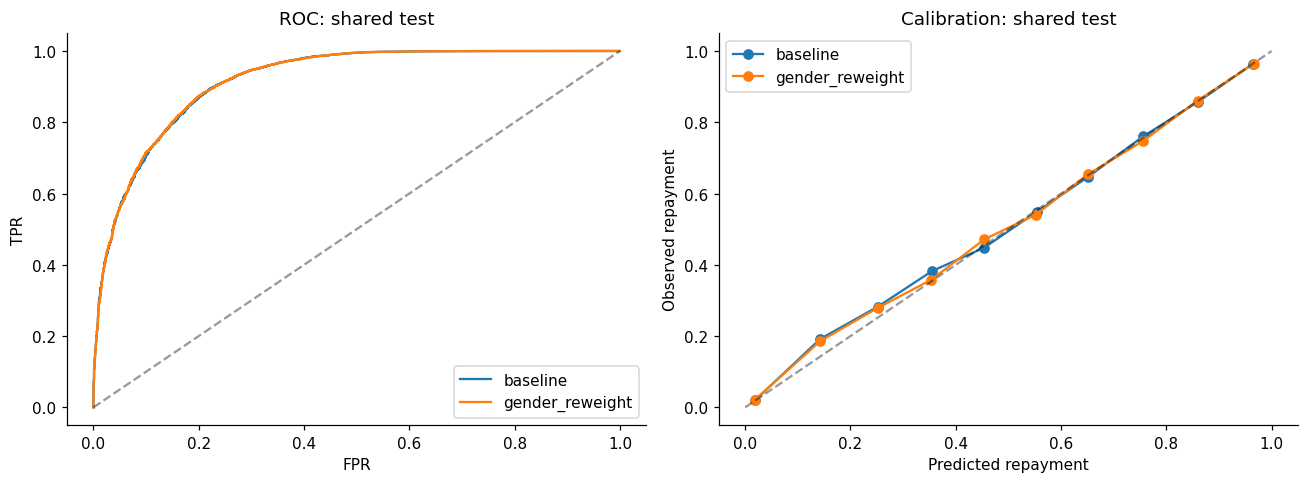

In [18]:
report_models={"baseline":baseline}
if SELECTED_NAME!="baseline":report_models[SELECTED_NAME]=selected
final_rows=[];predictions={}
for dataset,df in [("independent_audit",audit),("shared_test_20k",shared_test)]:
    for name,bundle in report_models.items():
        p=predict(bundle,df);predictions[(dataset,name)]=p
        final_rows.append({"Dataset":dataset,"Variant":name,**metrics(df,p,bundle["threshold"])})
        detail=group_metrics(df,p,bundle["threshold"])
        table(f"{dataset}_{name}_groups",detail,False)
        table(f"{dataset}_{name}_gaps",gaps(detail),False)
        table(f"{dataset}_{name}_tost",equivalence_tests(detail),False)
        
        '''
        conditional,cal=conditional_audit(df,p,bundle["threshold"])
        table(f"{dataset}_{name}_conditional",conditional,False)
        table(f"{dataset}_{name}_calibration",cal,False)
        '''

        table(f"{dataset}_{name}_predictions",pd.DataFrame({ID:df[ID].to_numpy(),"Actual":df[TARGET].to_numpy(),
            "P_repaid":p,"Threshold":bundle["threshold"],"Approve":p>=bundle["threshold"]}),False)
final_metrics=table("final_metrics",final_rows)

def bootstrap_comparison(df,model_dict,probs):
    rng=np.random.default_rng(SEED);store={name:[] for name in model_dict}
    for _ in range(BOOTSTRAP_B):
        ix=rng.integers(0,len(df),len(df));part=df.iloc[ix]
        if part[TARGET].nunique()<2:continue
        for name,b in model_dict.items():
            p=probs[name][ix]
            store[name].append([roc_auc_score(part[TARGET],p),profits(part,p>=b["threshold"]).mean()])
    rows=[]
    for name,vals in store.items():
        for j,metric in enumerate(["AUC","PNL_per_applicant"]):
            lo,hi=np.quantile(np.asarray(vals)[:,j],[.025,.975])
            rows.append({"Variant":name,"Metric":metric,"CI_low":lo,"CI_high":hi})
    if len(store)==2:
        other=next(n for n in store if n!="baseline")
        delta=np.asarray(store[other])-np.asarray(store["baseline"])
        for j,metric in enumerate(["AUC","PNL_per_applicant"]):
            lo,hi=np.quantile(delta[:,j],[.025,.975])
            rows.append({"Variant":other+" minus baseline (paired)","Metric":metric,"CI_low":lo,"CI_high":hi})
    return pd.DataFrame(rows)

table("shared_test_confidence_intervals",bootstrap_comparison(shared_test,report_models,
    {n:predictions[("shared_test_20k",n)] for n in report_models}))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for name,b in report_models.items():
    p=predictions[("shared_test_20k",name)]
    fpr,tpr,_=roc_curve(shared_test[TARGET],p);axes[0].plot(fpr,tpr,label=name)
    bins=pd.cut(p,np.linspace(0,1,11),include_lowest=True)
    cal=pd.DataFrame({"bin":bins,"p":p,"y":shared_test[TARGET].to_numpy()}).groupby("bin",observed=True).agg(
        Mean_p=("p","mean"),Observed=("y","mean"),N=("y","size")).reset_index()
    table("calibration_curve_"+name,cal,False)
    axes[1].plot(cal.Mean_p,cal.Observed,"o-",label=name)
for ax in axes:ax.plot([0,1],[0,1],"k--",alpha=.4);ax.legend()
axes[0].set(xlabel="FPR",ylabel="TPR",title="ROC: shared test")
axes[1].set(xlabel="Predicted repayment",ylabel="Observed repayment",title="Calibration: shared test")
figure("final_roc_calibration")

## 16. Four-Dimension Trade-offs, Interpretation, and Deliverables
The summary below is generated from this run's results; previous AUC or profit figures are not prefilled.
It covers XGBoost variants only. A deployment recommendation comparing all three models still requires comparable results from the other two teammates.
Fairness and stability conclusions are limited to these data, thresholds, groups, and experimental settings. They do not constitute legal certification or causal conclusions.

In [19]:
print("===== Four-Dimension Summary of This Run =====")
print("Mode:",MODE,"; final submission must use complete full-mode outputs.")
print("Prediction and profit: see final_metrics and paired confidence intervals; AP is exported with repayment and default as the respective positive classes.")
top_features=importance.sort_values("SHAP_rank").Feature.head(3).tolist()
print("Interpretability: top three global SHAP features:",", ".join(top_features),"; see customer_cases for the three customer examples.")
print(
    "Stability: baseline mean importance L2=",
    round(stability.Importance_L2.mean(), 4)
)
print("Fairness: selected using the predefined development-set rule:",SELECTED_NAME,"; do not change the selected approach based on test results.")
print(
    "Limitations: XPER background-sampling error; "
    "local LIME fidelity; "
    "correlated feature combinations in FPDP; "
    "small-group diagnostics."
)
coverage=pd.DataFrame([
    ["Predictive performance","AUC/AP/Gini/KS/Brier/P&L/confidence intervals/XPER","3, 8, 15"],
    ["Interpretability","SHAP/PI/PDP/ICE/LIME/disagreements/customer cases","5–8"],
    ["Stability","Common-sample performance/importance distances/customer contributions/decision flips/noise/training constraints","3, 9–10"],
    ["Fairness","Group gaps/TOST/FPDP/candidate associations/CMH/binned sufficiency/mitigation trade-offs","4, 11–15"]],
    columns=["Dimension","Implementation","Sections"])
table("course_coverage",coverage)

===== Four-Dimension Summary of This Run =====
Mode: full ; final submission must use complete full-mode outputs.
Prediction and profit: see final_metrics and paired confidence intervals; AP is exported with repayment and default as the respective positive classes.
Interpretability: top three global SHAP features: employment_status, debt_to_income_ratio, credit_score ; see customer_cases for the three customer examples.
Stability: baseline mean importance L2= 0.0271
Fairness: selected using the predefined development-set rule: gender_reweight ; do not change the selected approach based on test results.
Limitations: XPER background-sampling error; local LIME fidelity; correlated feature combinations in FPDP; small-group diagnostics.


,Dimension,Implementation,Sections
0,Predictive performance,AUC/AP/Gini/KS/Brier/P&L/confidence intervals/...,"3, 8, 15"
1,Interpretability,SHAP/PI/PDP/ICE/LIME/disagreements/customer cases,5–8
2,Stability,Common-sample performance/importance distances...,"3, 9–10"
3,Fairness,Group gaps/TOST/FPDP/candidate associations/CM...,"4, 11–15"


,Dimension,Implementation,Sections
0,Predictive performance,AUC/AP/Gini/KS/Brier/P&L/confidence intervals/...,"3, 8, 15"
1,Interpretability,SHAP/PI/PDP/ICE/LIME/disagreements/customer cases,5–8
2,Stability,Common-sample performance/importance distances...,"3, 9–10"
3,Fairness,Group gaps/TOST/FPDP/candidate associations/CM...,"4, 11–15"


In [16]:
def file_hash(path):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        for block in iter(lambda:f.read(1024*1024),b""):h.update(block)
    return h.hexdigest()

# Save feature order, category levels, and threshold for inference, not just trees without their preprocessing.
for name,b in variants.items():
    b["model"].save_model(str(OUT/(name+".json")))
    # Custom-objective closures are unsuitable for pickle; rebuild an inference-only object from the portable model.
    inference_model=XGBClassifier()
    inference_model.load_model(str(OUT/(name+".json")))
    inference_model.set_params(objective="binary:logistic")
    payload={k:v for k,v in b.items() if k not in {"threshold_curve","model"}}
    payload["model"]=inference_model
    joblib.dump(payload,OUT/(name+".joblib"))
    reloaded=joblib.load(OUT/(name+".joblib"))
    np.testing.assert_allclose(predict(reloaded,explain_df.head(10)),predict(b,explain_df.head(10)),atol=1e-7)
config={"run_id":RUN_ID,"mode":MODE,"project_root":str(PROJECT_ROOT),"features":FEATURES,
    "seed":SEED,"seeds":SEEDS,"trees_limit":N_ESTIMATORS,"split_fractions":{
        "fit":.6,"early_stop":.1,"threshold":.1,"comparison":.1,"audit":.1},
    "selected_variant":SELECTED_NAME,"threshold":selected["threshold"],"positive_class":"repayment",
    "delta":DELTA,"alpha":ALPHA,"min_group_n":MIN_GROUP_N,
    "anchor_source":"intersection of all fit sets; internal train/early-stop/threshold split",
    "selection":{"max_auc_loss":MAX_AUC_LOSS,"max_pnl_loss":MAX_PNL_LOSS,
        "objective":"minimize worst approval gap; EO gap must not worsen"},
    "xper":{"sample_size":len(xper_sample),"background_draws":XPER_DRAWS,"all_coalitions":2**len(FEATURES),
        "economic_context":"factual contract amounts/rates held fixed"},
    "versions":{n:version(n) for n in ["numpy","pandas","scipy","scikit-learn","xgboost","shap","matplotlib"]},
    "source_hashes":{name:file_hash(PROJECT_ROOT/"data"/name) for name in ["train.csv","test_eval_20k.csv"]}
    }
with open(OUT/"run_config.json","w",encoding="utf8") as f:json.dump(config,f,ensure_ascii=False,indent=2)
print("Complete results saved to",OUT.resolve())

Complete results saved to /Users/oscar/VSCodeWorkspace/isaf-project/MLModels/blackbox_extended_runs/full/20260924T085553Z_2925d2
